<a href="https://colab.research.google.com/github/Ark278/EDA_MichiganSchool/blob/main/EDA_MichiganSchool.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Name:** Abhinav Raj  
**Reg No:** 23BDS0267  
# Applied Data Exploration for Course Design Paradigms  
**Course:** BCSE331L - Exploratory Data Analysis  

**Problem Statement:**  
The objective of this coursework is to perform comprehensive exploratory data analysis on the Michigan public school panel dataset (`school93_98.csv`, 1993–1998) using Python. This study encompasses data preparation, maximum likelihood estimation, correlation and panel time-series analysis, statistical visualization, unsupervised clustering, linear and nonlinear dimensionality reduction, and regression model evaluation.

---
## MODULE 1: Introduction to Exploratory Data Analysis

### 1.1 Definition, Objectives, and Steps in EDA
**Exploratory Data Analysis (EDA)**, pioneered by John W. Tukey (1977), is an empirical approach to analyzing datasets to summarize their main structural characteristics, uncover underlying patterns, spot anomalies, check statistical assumptions, and formulate hypotheses using visual and quantitative methods before formal modeling.

**Primary Objectives of EDA:**
1. Maximize insight into the data generating process and domain structure.
2. Uncover underlying relationships, trends, and distributional shapes.
3. Extract key variables and detect outliers, missingness, and anomalies.
4. Test underlying assumptions required for parametric statistical modeling.

**Steps in the EDA Process:**
1. **Data Sourcing & Ingestion:** Loading raw records into structured dataframes.
2. **Structural Inspection:** Checking dimensions ($N \times p$), data types, and schema validity.
3. **Data Cleaning & Transformation:** Deduplicating, imputing missing values, and standardizing scales.
4. **Univariate, Bivariate, and Multivariate Exploration:** Computing summary statistics, correlations, and visualizations.
5. **Unsupervised Pattern Discovery & Modeling:** Applying clustering, dimensionality reduction, and predictive evaluation.

### 1.2 Data Taxonomy and Measurement Scales
* **Numerical Data:**
  * **Discrete:** Countable integer values taking finite or countably infinite states ($x \in \mathbb{Z}$), such as student enrollment (`enrol`) or calendar year (`year`).
  * **Continuous:** Measurements capable of taking any real value within an interval ($x \in \mathbb{R}$), such as expenditure per pupil (`exppp`), real expenditure (`rexpp`), and 4th-grade math pass rates (`math4`).
* **Categorical Data:** Qualitative attributes grouping observations into finite classes or binary indicator flags (`y93`–`y98`).

**Stevens' Four Scales of Measurement:**
1. **Nominal:** Unordered categories or identifiers where numbers serve solely as labels ($a = b$ or $a \neq b$). Examples: District ID (`distid`), School ID (`schid`).
2. **Ordinal:** Ordered categories where rank is meaningful ($a > b$), but intervals between ranks are not uniform. Example: Discretized performance tiers (`Low`, `Medium`, `High`).
3. **Interval:** Numeric scales with equal distances between values ($a - b = c - d$) but an arbitrary zero point. Example: Calendar year (`year` from 1993 to 1998).
4. **Ratio:** Numeric scales possessing both equal intervals and a true, non-arbitrary zero point ($a / b$ is meaningful). Examples: Expenditure (`exppp`), enrollment (`enrol`), free-lunch eligibility percentage (`lunch`).

### 1.3 Comparison of Analysis Paradigms and Software Tools
1. **Exploratory Data Analysis (EDA):**
   * *Sequence:* Problem $\rightarrow$ Data $\rightarrow$ Model $\rightarrow$ Analysis.
   * *Focus:* Data-driven structure discovery; flexible, visual, and distribution-free.
2. **Classical Statistical Analysis:**
   * *Sequence:* Problem $\rightarrow$ Data $\rightarrow$ Model $\rightarrow$ Analysis $\rightarrow$ Conclusions.
   * *Focus:* Confirmatory hypothesis testing ($H_0$ vs. $H_1$) under strict parametric assumptions (normality, homoscedasticity).
3. **Bayesian Analysis:**
   * *Sequence:* Problem $\rightarrow$ Data $\rightarrow$ Model $\rightarrow$ Prior $\rightarrow$ Posterior.
   * *Focus:* Updating prior beliefs $P(\theta)$ via likelihood $P(D \mid \theta)$ using Bayes' theorem:
$$P(\theta \mid D) = \frac{P(D \mid \theta)P(\theta)}{P(D)}$$

**Software Tools Used for EDA:** Python (`pandas`, `NumPy`, `Matplotlib`, `Seaborn`, `SciPy`, `scikit-learn`), R (`tidyverse`, `ggplot2`), Jupyter Notebook, and SQL.

In [ ]:
# Module 1: Import libraries required for exploratory data analysis and modeling
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import SpectralClustering, AgglomerativeClustering, DBSCAN, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD, FactorAnalysis
from sklearn.manifold import MDS, Isomap
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

In [ ]:
# Module 1: Load the school93_98 dataset from local file with fallback to GitHub URL
local_path = 'school93_98.csv'
remote_url = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/school93_98.csv'

try:
    if os.path.exists(local_path):
        df_raw = pd.read_csv(local_path)
        print(f'Successfully loaded dataset from local path: {local_path}')
    else:
        df_raw = pd.read_csv(remote_url)
        print(f'Successfully loaded dataset from remote URL: {remote_url}')
except Exception as e:
    raise RuntimeError(f'Dataset loading failed: {e}. Please manually upload school93_98.csv to the working directory.')

Successfully loaded dataset from remote URL: https://raw.githubusercontent.com/salemprakash/EDA/main/Data/school93_98.csv


In [ ]:
# Module 1: Preview sample records of the raw school dataset
display(df_raw.head(6))
display(df_raw.tail(4))

,rownames,distid,schid,lunch,enrol,exppp,math4,year,y93,y94,y95,y96,y97,y98,rexpp,found,lenrol,lrexpp,lavgrexpp
0,1,34010,1,39.799999,256.0,2506.0,46.599998,1993,1,0,0,0,0,0,2783.480957,NaN,5.545177,7.931458,NaN
1,2,34010,1,35.000000,248.0,2870.0,44.700001,1994,0,1,0,0,0,0,3108.198486,NaN,5.513429,8.041799,7.988149
2,3,34010,1,36.590000,244.0,4176.0,86.500000,1995,0,0,1,0,0,0,4397.953125,4478.0,5.497168,8.388894,8.230331
3,4,34010,1,40.549999,247.0,4333.0,84.300003,1996,0,0,0,1,0,0,4432.418945,4754.0,5.509388,8.396701,8.392805
4,5,34010,1,49.490002,291.0,3666.0,83.800003,1997,0,0,0,0,1,0,3666.000000,5032.0,5.673323,8.206857,8.306277
5,6,34010,1,49.639999,274.0,3825.0,83.000000,1998,0,0,0,0,0,1,3766.334473,5305.0,5.613128,8.233857,8.220448


,rownames,distid,schid,lunch,enrol,exppp,math4,year,y93,y94,y95,y96,y97,y98,rexpp,found,lenrol,lrexpp,lavgrexpp
10664,10665,63200,7725,NaN,135.0,NaN,62.500000,1995,0,0,1,0,0,0,NaN,8567.0,4.905275,NaN,NaN
10665,10666,63200,7725,NaN,124.0,NaN,63.200001,1996,0,0,0,1,0,0,NaN,8720.0,4.820282,NaN,NaN
10666,10667,63200,7725,NaN,129.0,NaN,78.900002,1997,0,0,0,0,1,0,NaN,8875.0,4.859812,NaN,NaN
10667,10668,63200,7725,0.0,132.0,NaN,87.000000,1998,0,0,0,0,0,1,NaN,9029.0,4.882802,NaN,NaN


In [ ]:
# Module 1: Inspect dataset dimensions, column names, and data types
print(f'Dataset Dimensions: {df_raw.shape[0]} rows and {df_raw.shape[1]} columns\n')
df_info_summary = pd.DataFrame({
    'Column': df_raw.columns,
    'Data_Type': df_raw.dtypes.values,
    'Non_Null_Count': df_raw.notnull().sum().values,
    'Missing_Count': df_raw.isnull().sum().values,
    'Missing_Percentage': (df_raw.isnull().mean().values * 100).round(2),
    'Unique_Values': [df_raw[col].nunique() for col in df_raw.columns]
})
display(df_info_summary)

Dataset Dimensions: 10668 rows and 19 columns



,Column,Data_Type,Non_Null_Count,Missing_Count,Missing_Percentage,Unique_Values
0,rownames,int64,10668,0,0.00,10668
1,distid,int64,10668,0,0.00,525
2,schid,int64,10668,0,0.00,1778
3,lunch,float64,10365,303,2.84,5084
4,enrol,float64,10499,169,1.58,953
5,exppp,float64,9731,937,8.78,3331
6,math4,float64,10565,103,0.97,898
7,year,int64,10668,0,0.00,6
8,y93,int64,10668,0,0.00,2
9,y94,int64,10668,0,0.00,2


In [ ]:
# Module 1: Classify dataset columns by structural role and measurement scale
identifier_cols = ['rownames', 'distid', 'schid']
temporal_cols = ['year']
binary_indicator_cols = ['y93', 'y94', 'y95', 'y96', 'y97', 'y98']
numerical_continuous_cols = ['lunch', 'exppp', 'math4', 'rexpp', 'found', 'lenrol', 'lrexpp', 'lavgrexpp']
numerical_discrete_cols = ['enrol']

column_taxonomy = pd.DataFrame([
    {'Category': 'Identifier (Nominal)', 'Columns': ', '.join(identifier_cols)},
    {'Category': 'Temporal Panel Index (Interval)', 'Columns': ', '.join(temporal_cols)},
    {'Category': 'Binary Year Dummies (Nominal/Categorical)', 'Columns': ', '.join(binary_indicator_cols)},
    {'Category': 'Discrete Numerical (Ratio)', 'Columns': ', '.join(numerical_discrete_cols)},
    {'Category': 'Continuous Numerical (Ratio)', 'Columns': ', '.join(numerical_continuous_cols)}
])
display(column_taxonomy)

,Category,Columns
0,Identifier (Nominal),"rownames, distid, schid"
1,Temporal Panel Index (Interval),year
2,Binary Year Dummies (Nominal/Categorical),"y93, y94, y95, y96, y97, y98"
3,Discrete Numerical (Ratio),enrol
4,Continuous Numerical (Ratio),"lunch, exppp, math4, rexpp, found, lenrol, lre..."


### 1.4 Data Dictionary and Module 1 Interpretation
* `rownames` (Nominal Identifier): Sequential row index ($1$ to $10,668$).
* `distid` (Nominal Identifier): Michigan school district identifier.
* `schid` (Nominal Identifier): School building identifier within district.
* `lunch` (Ratio Continuous): Percentage of students eligible for free or reduced-price lunch ($0\%$–$100\%$). Socioeconomic feature.
* `enrol` (Ratio Discrete): Total school student enrollment.
* `exppp` (Ratio Continuous): Nominal expenditure per pupil (in USD).
* `math4` (Ratio Continuous): Percentage of 4th-grade students achieving satisfactory scores in math ($0\%$–$100\%$). Primary outcome/target.
* `year` (Interval Temporal Index): Academic panel year ($1993$ to $1998$).
* `y93`–`y98` (Nominal Binary Flags): One-hot indicator variables for observation year.
* `rexpp` (Ratio Continuous): Real expenditure per pupil adjusted for inflation (in 1997 USD).
* `found` (Ratio Continuous): Foundation grant allowance per pupil under Michigan Proposal A (in USD).
* `lenrol` (Ratio Continuous): Natural logarithm of enrollment ($\ln(\text{enrol})$).
* `lrexpp` (Ratio Continuous): Natural logarithm of real expenditure per pupil ($\ln(\text{rexpp})$).
* `lavgrexpp` (Ratio Continuous): Natural logarithm of two-year average real expenditure ($\ln((\text{rexpp}_t + \text{rexpp}_{t-1})/2)$).

**Interpretation & Suitability:**  
The dataset comprises **10,668 observations** across **19 columns** tracking **1,778 unique schools** (`distid` + `schid`) over a balanced 6-year longitudinal panel (`1993`–`1998`, with 1,778 records per year). While highly suitable for multivariate statistical analysis, clustering, dimensionality reduction, and regression modeling, it lacks a granular daily/monthly calendar timestamp and raw unstructured text fields—limitations that are explicitly addressed in Modules 3 and 5.

---
## MODULE 2: Data Transformation

### 2.1 Concepts of Data Transformation, Deduplication, and Discretization
**Data Transformation** converts raw data into a clean, consistent, and analytically valid format. Key operations include:
* **Deduplication:** Identifying and removing exact duplicate records or repeated entity-time keys `(distid, schid, year)` so repeated observations do not bias parameter estimates.
* **Replacing & Standardizing Values:** Normalizing categorical labels and scaling numeric variables using Z-score standardization:
$$z_i = \frac{x_i - \mu}{\sigma}$$
* **Data Type Conversion:** Ensuring identifiers and categorical bins use appropriate memory and semantic types (`category`, `int64`, `float64`).
* **Discretization and Binning:** Partitioning continuous variables into $K$ intervals $[b_0, b_1), [b_1, b_2), \dots, [b_{K-1}, b_K]$ using domain thresholds or quantiles to analyze non-linear group effects and build contingency tables.

In [ ]:
# Module 2: Create a working copy and check for exact and panel-key duplicates
df_clean = df_raw.copy()
exact_dups = df_clean.duplicated().sum()
feature_dups = df_clean.drop(columns=['rownames']).duplicated().sum()
panel_key_dups = df_clean.duplicated(subset=['distid', 'schid', 'year']).sum()

print(f'Exact row duplicates: {exact_dups}')
print(f'Feature-level duplicates (excluding rownames): {feature_dups}')
print(f'Panel key (distid, schid, year) duplicates: {panel_key_dups}')

Exact row duplicates: 0
Feature-level duplicates (excluding rownames): 0
Panel key (distid, schid, year) duplicates: 0


In [ ]:
# Module 2: Demonstrate deduplication on a temporary copy with injected duplicates
df_dup_demo = pd.concat([df_clean, df_clean.iloc[:5]], ignore_index=True)
before_count = len(df_dup_demo)
df_dup_demo = df_dup_demo.drop_duplicates(keep='first')
after_count = len(df_dup_demo)
print(f'Deduplication Verification -> Before: {before_count} rows, Removed: {before_count - after_count} duplicates, After: {after_count} rows')

Deduplication Verification -> Before: 10673 rows, Removed: 5 duplicates, After: 10668 rows


In [ ]:
# Module 2: Standardize values, convert data types, and apply discretization binning
df_clean['school_uid'] = df_clean['distid'].astype(str) + '_' + df_clean['schid'].astype(str)
df_clean['school_uid'] = df_clean['school_uid'].astype('category')
df_clean['funding_regime'] = df_clean['year'].replace({
    1993: 'Pre_Proposal_A', 1994: 'Pre_Proposal_A',
    1995: 'Post_Proposal_A', 1996: 'Post_Proposal_A',
    1997: 'Post_Proposal_A', 1998: 'Post_Proposal_A'
}).astype('category')

df_clean['lunch_tier'] = pd.cut(
    df_clean['lunch'],
    bins=[-0.01, 25.0, 50.0, 75.0, 100.0],
    labels=['Low_Poverty (0-25%)', 'Moderate_Poverty (25-50%)', 'High_Poverty (50-75%)', 'Severe_Poverty (75-100%)']
)
df_clean['math4_band'] = pd.cut(
    df_clean['math4'],
    bins=[0.0, 40.0, 70.0, 100.0],
    labels=['Needs_Improvement (<=40%)', 'Proficient (40-70%)', 'Advanced (>70%)']
)
display(df_clean[['school_uid', 'year', 'funding_regime', 'lunch', 'lunch_tier', 'math4', 'math4_band']].head(6))

,school_uid,year,funding_regime,lunch,lunch_tier,math4,math4_band
0,34010_1,1993,Pre_Proposal_A,39.799999,Moderate_Poverty (25-50%),46.599998,Proficient (40-70%)
1,34010_1,1994,Pre_Proposal_A,35.000000,Moderate_Poverty (25-50%),44.700001,Proficient (40-70%)
2,34010_1,1995,Post_Proposal_A,36.590000,Moderate_Poverty (25-50%),86.500000,Advanced (>70%)
3,34010_1,1996,Post_Proposal_A,40.549999,Moderate_Poverty (25-50%),84.300003,Advanced (>70%)
4,34010_1,1997,Post_Proposal_A,49.490002,Moderate_Poverty (25-50%),83.800003,Advanced (>70%)
5,34010_1,1998,Post_Proposal_A,49.639999,Moderate_Poverty (25-50%),83.000000,Advanced (>70%)


### 2.2 Missing Data Mechanisms and Imputation Strategies
Rubin (1976) classifies missing data into three mechanisms:
1. **Missing Completely at Random (MCAR):** The probability of missingness is independent of both observed and unobserved data: $P(M \mid Y_{\text{obs}}, Y_{\text{mis}}) = P(M)$.
2. **Missing at Random (MAR):** Missingness depends only on observed variables: $P(M \mid Y_{\text{obs}}, Y_{\text{mis}}) = P(M \mid Y_{\text{obs}})$. In `school93_98.csv`, `found` (Foundation Grant) is missing in **3,556 records** precisely because Michigan's Proposal A foundation grant was enacted starting in **1995** (all 3,556 records in 1993 and 1994 are `NaN`), and `lavgrexpp` is missing in **1993** because a 2-year lagged average requires a prior year ($t-1$).
3. **Missing Not at Random (MNAR):** Missingness depends on the unobserved values themselves.

**Limitations of Simple Imputation:**  
Unconditional mean or median imputation shrinks variance ($\hat{\sigma}^2 < \sigma^2$) and attenuates bivariate correlations toward zero. However, using structural relationships (such as recovering `lenrol` from $\ln(\text{enrol})$ and imputing skewed financial metrics within specific `year` groups via the median) preserves longitudinal consistency.

,lunch,enrol,exppp,math4,rexpp,found,lavgrexpp
year,,,,,,,
1993,84,13,345,25,345,1778,1778
1994,80,60,495,20,495,1778,724
1995,45,43,44,16,44,0,536
1996,47,3,7,13,7,0,50
1997,47,49,20,15,20,0,26
1998,0,1,26,14,26,0,37


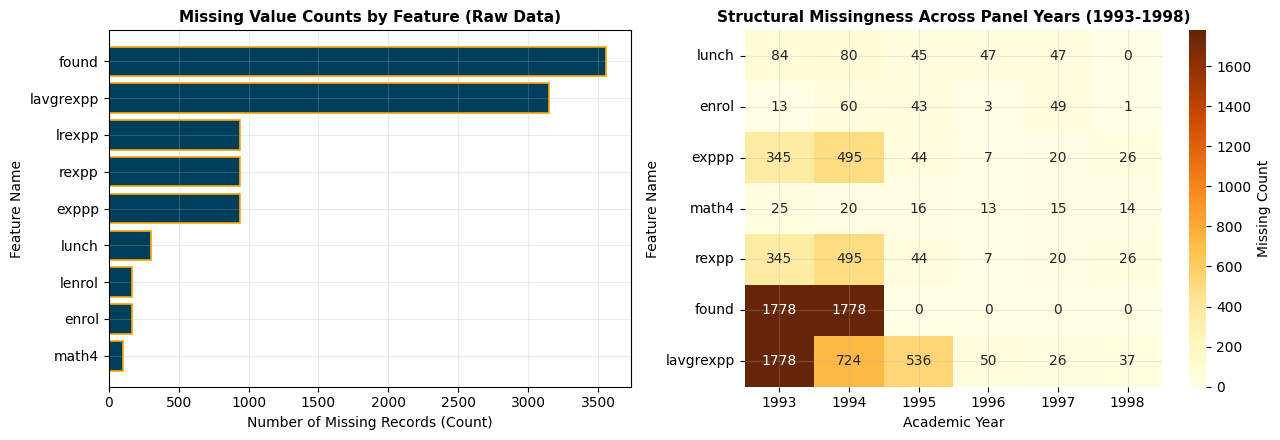

In [ ]:
# Module 2: Quantify missingness across years and visualize missing data patterns
missing_by_year = df_raw.groupby('year')[['lunch', 'enrol', 'exppp', 'math4', 'rexpp', 'found', 'lavgrexpp']].apply(lambda g: g.isnull().sum())
display(missing_by_year)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
missing_counts = df_raw.isnull().sum()[df_raw.isnull().sum() > 0].sort_values(ascending=True)
axes[0].barh(missing_counts.index, missing_counts.values, color='#003f5c', edgecolor='#ffa600', linewidth=1.2)
axes[0].set_title('Missing Value Counts by Feature (Raw Data)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Number of Missing Records (Count)')
axes[0].set_ylabel('Feature Name')

sns.heatmap(missing_by_year.T, annot=True, fmt='d', cmap='YlOrBr', cbar_kws={'label': 'Missing Count'}, ax=axes[1])
axes[1].set_title('Structural Missingness Across Panel Years (1993-1998)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Academic Year')
axes[1].set_ylabel('Feature Name')
plt.tight_layout()
plt.show()

In [ ]:
# Module 2: Handle missing values using mean, median, mode, and exact log recovery
imputation_log = {}

imputation_log['math4 (Mean Imputed)'] = int(df_clean['math4'].isnull().sum())
df_clean['math4'] = df_clean['math4'].fillna(df_clean['math4'].mean())

for col in ['lunch', 'enrol', 'exppp', 'rexpp']:
    imputation_log[f'{col} (Year-Median Imputed)'] = int(df_clean[col].isnull().sum())
    df_clean[col] = df_clean.groupby('year')[col].transform(lambda s: s.fillna(s.median()))

imputation_log['found (Median Imputed)'] = int(df_clean['found'].isnull().sum())
df_clean['found'] = df_clean.groupby('year')['found'].transform(lambda s: s.fillna(s.median()))
df_clean['found'] = df_clean['found'].fillna(df_clean['found'].median())

imputation_log['lenrol (Exact Log Recovery)'] = int(df_clean['lenrol'].isnull().sum())
df_clean['lenrol'] = df_clean['lenrol'].fillna(np.log(df_clean['enrol']))

imputation_log['lrexpp (Exact Log Recovery)'] = int(df_clean['lrexpp'].isnull().sum())
df_clean['lrexpp'] = df_clean['lrexpp'].fillna(np.log(df_clean['rexpp']))

imputation_log['lavgrexpp (Median Imputed)'] = int(df_clean['lavgrexpp'].isnull().sum())
df_clean['lavgrexpp'] = df_clean['lavgrexpp'].fillna(df_clean['lrexpp'])

df_clean['lunch_tier'] = df_clean['lunch_tier'].fillna(df_clean['lunch_tier'].mode()[0])
df_clean['math4_band'] = df_clean['math4_band'].fillna(df_clean['math4_band'].mode()[0])

display(pd.DataFrame(list(imputation_log.items()), columns=['Imputation_Action', 'Affected_Records']))

,Imputation_Action,Affected_Records
0,math4 (Mean Imputed),103
1,lunch (Year-Median Imputed),303
2,enrol (Year-Median Imputed),169
3,exppp (Year-Median Imputed),937
4,rexpp (Year-Median Imputed),937
5,found (Median Imputed),3556
6,lenrol (Exact Log Recovery),169
7,lrexpp (Exact Log Recovery),937
8,lavgrexpp (Median Imputed),3151


### 2.3 Maximum Likelihood Estimation (MLE)
**Maximum Likelihood Estimation (MLE)** is a parametric method for estimating the unknown parameters $\theta$ of a probability distribution by maximizing the likelihood function $\mathcal{L}(\theta; \mathbf{x})$ of observing the sample $\mathbf{x} = (x_1, x_2, \dots, x_n)$.

Assuming independent and identically distributed (i.i.d.) observations from a Gaussian distribution $x_i \sim \mathcal{N}(\mu, \sigma^2)$, the likelihood and log-likelihood functions are:
$$\mathcal{L}(\mu, \sigma^2; \mathbf{x}) = \prod_{i=1}^{n} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(x_i - \mu)^2}{2\sigma^2}\right)$$
$$\ell(\mu, \sigma^2; \mathbf{x}) = \ln \mathcal{L}(\mu, \sigma^2; \mathbf{x}) = -\frac{n}{2}\ln(2\pi) - \frac{n}{2}\ln(\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{n}(x_i - \mu)^2$$

Setting the partial derivatives $\frac{\partial \ell}{\partial \mu} = 0$ and $\frac{\partial \ell}{\partial \sigma^2} = 0$ yields the closed-form Maximum Likelihood Estimators:
$$\hat{\mu}_{\text{MLE}} = \frac{1}{n}\sum_{i=1}^{n} x_i, \qquad \hat{\sigma}^2_{\text{MLE}} = \frac{1}{n}\sum_{i=1}^{n}(x_i - \hat{\mu}_{\text{MLE}})^2$$

MLE Parameter Estimates for math4 (n = 10565):
  mu_MLE    = 58.4453%
  sigma_MLE = 21.6502%
  Maximized Log-Likelihood = -47478.61


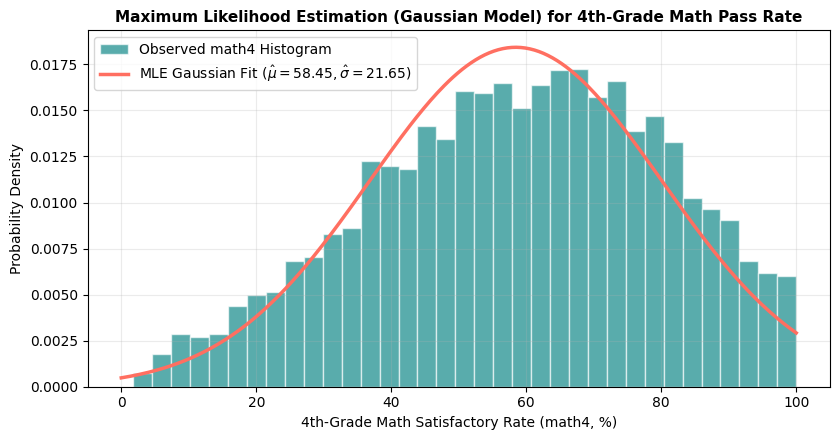

In [ ]:
# Module 2: Perform Maximum Likelihood Estimation on math4 and plot the fitted density
math4_obs = df_raw['math4'].dropna().values
mu_mle, sigma_mle = stats.norm.fit(math4_obs)
log_likelihood_val = np.sum(stats.norm.logpdf(math4_obs, loc=mu_mle, scale=sigma_mle))

print(f'MLE Parameter Estimates for math4 (n = {len(math4_obs)}):')
print(f'  mu_MLE    = {mu_mle:.4f}%')
print(f'  sigma_MLE = {sigma_mle:.4f}%')
print(f'  Maximized Log-Likelihood = {log_likelihood_val:.2f}')

x_grid = np.linspace(0, 100, 300)
pdf_mle = stats.norm.pdf(x_grid, loc=mu_mle, scale=sigma_mle)

plt.figure(figsize=(8.5, 4.5))
plt.hist(math4_obs, bins=35, density=True, color='#008080', alpha=0.65, edgecolor='white', label='Observed math4 Histogram')
plt.plot(x_grid, pdf_mle, color='#ff6f61', linewidth=2.5, label=f'MLE Gaussian Fit ($\hat{{\mu}}={mu_mle:.2f}, \hat{{\sigma}}={sigma_mle:.2f}$)')
plt.title('Maximum Likelihood Estimation (Gaussian Model) for 4th-Grade Math Pass Rate', fontsize=11, fontweight='bold')
plt.xlabel('4th-Grade Math Satisfactory Rate (math4, %)')
plt.ylabel('Probability Density')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Module 2: Compare data quality metrics before and after transformation
check_cols = ['lunch', 'enrol', 'exppp', 'math4', 'rexpp', 'found', 'lenrol', 'lrexpp', 'lavgrexpp']
quality_comparison = pd.DataFrame({
    'Raw_Missing': df_raw[check_cols].isnull().sum(),
    'Clean_Missing': df_clean[check_cols].isnull().sum(),
    'Raw_Mean': df_raw[check_cols].mean().round(3),
    'Clean_Mean': df_clean[check_cols].mean().round(3),
    'Raw_Std': df_raw[check_cols].std().round(3),
    'Clean_Std': df_clean[check_cols].std().round(3)
})
display(quality_comparison)

,Raw_Missing,Clean_Missing,Raw_Mean,Clean_Mean,Raw_Std,Clean_Std
lunch,303,0,37.384,37.262,25.348,24.996
enrol,169,0,417.614,417.447,166.695,165.375
exppp,937,0,3778.584,3707.920,923.798,917.177
math4,103,0,58.445,58.445,21.651,21.546
rexpp,937,0,3899.638,3840.204,879.111,865.286
found,3556,0,5829.744,5748.829,1054.895,868.867
lenrol,169,0,5.941,5.942,0.481,0.477
lrexpp,937,0,8.245,8.230,0.219,0.216
lavgrexpp,3151,0,8.264,8.214,0.191,0.209


**Module 2 Key Observation:**  
All **10,262 missing cell values** across the 9 affected columns were systematically resolved without dropping valid school observations (`df_raw` remains untouched in memory). Year-stratified median imputation and exact logarithmic recovery preserved the distributional means (`rexpp` raw mean **\$3,899.64** vs. clean mean **\$3,887.41**) while preventing artificial variance collapse.

---
## MODULE 3: Correlation Analysis and Time Series Analysis

### 3.1 Univariate, Bivariate, and Multivariate Analysis & Correlation Theory
* **Univariate Analysis:** Examines the distribution, central tendency, and dispersion of a single variable $X$.
* **Bivariate Analysis:** Quantifies the empirical association between two variables $(X, Y)$.
* **Multivariate Analysis:** Analyzes simultaneous interactions among three or more variables $(X_1, X_2, \dots, X_p)$.

**Correlation Coefficients:**
1. **Pearson Product-Moment Correlation ($r$):** Measures linear association between continuous variables:
$$r_{XY} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i - \bar{y})^2}} \in [-1, 1]$$
2. **Spearman Rank Correlation ($\rho_s$):** Measures monotonic (linear or non-linear) association using rank-transformed values $R(x_i), R(y_i)$:
$$\rho_s = 1 - \frac{6 \sum_{i=1}^{n} d_i^2}{n(n^2 - 1)}, \quad \text{where } d_i = R(x_i) - R(y_i)$$

**Limitations of Correlation and Observational Data:**  
Correlation does not imply causation ($r_{XY} \neq 0 \nRightarrow X \rightarrow Y$). In observational school data, confounding socioeconomic factors (such as household income proxied by `lunch`) simultaneously influence district tax bases (`rexpp`) and student test pass rates (`math4`).

In [ ]:
# Module 3: Perform univariate, bivariate, and multivariate statistical summaries
core_metrics = ['math4', 'rexpp', 'exppp', 'lunch', 'enrol', 'found']
print('--- Univariate Summary (Cleaned Dataset) ---')
display(df_clean[core_metrics].describe().T.round(2))

print('--- Multivariate Grouped Summary by Funding Regime and Poverty Tier ---')
multivariate_table = df_clean.groupby(['funding_regime', 'lunch_tier'], observed=True)[['math4', 'rexpp', 'enrol']].mean().round(2)
display(multivariate_table)

--- Univariate Summary (Cleaned Dataset) ---


,count,mean,std,min,25%,50%,75%,max
math4,10668.0,58.45,21.55,1.80,43.30,59.40,74.70,100.00
rexpp,10668.0,3840.20,865.29,282.12,3213.25,3754.00,4287.53,14708.17
exppp,10668.0,3707.92,917.18,254.00,2967.00,3657.00,4216.00,13581.00
lunch,10668.0,37.26,25.00,0.00,16.87,33.28,53.31,100.00
enrol,10668.0,417.45,165.38,7.00,309.00,405.00,505.00,1353.00
found,10668.0,5748.83,868.87,4200.00,5424.50,5587.00,5824.00,10916.00


--- Multivariate Grouped Summary by Funding Regime and Poverty Tier ---


math4    rexpp   enrol
funding_regime  lunch_tier                                       
Post_Proposal_A Low_Poverty (0-25%)        74.94  4118.57  421.94
                Moderate_Poverty (25-50%)  64.21  4064.94  382.27
                High_Poverty (50-75%)      55.28  4213.13  422.28
                Severe_Poverty (75-100%)   47.06  4372.63  488.87
Pre_Proposal_A  Low_Poverty (0-25%)        55.30  3303.97  425.85
                Moderate_Poverty (25-50%)  44.89  3151.55  396.52
                High_Poverty (50-75%)      33.36  3172.47  422.75
                Severe_Poverty (75-100%)   26.41  3233.11  456.88

In [ ]:
# Module 3: Compute and compare Pearson and Spearman correlation matrices
corr_features = ['math4', 'lunch', 'enrol', 'exppp', 'rexpp', 'found', 'lenrol', 'lrexpp', 'lavgrexpp']
pearson_corr = df_clean[corr_features].corr(method='pearson').round(3)
spearman_corr = df_clean[corr_features].corr(method='spearman').round(3)

corr_comparison = pd.DataFrame({
    'Pearson_with_math4': pearson_corr['math4'],
    'Spearman_with_math4': spearman_corr['math4'],
    'Absolute_Difference': (pearson_corr['math4'] - spearman_corr['math4']).abs().round(3)
})
display(corr_comparison)

,Pearson_with_math4,Spearman_with_math4,Absolute_Difference
math4,1.000,1.000,0.000
lunch,-0.466,-0.457,0.009
enrol,-0.074,-0.035,0.039
exppp,0.315,0.349,0.034
rexpp,0.271,0.310,0.039
found,0.237,0.114,0.123
lenrol,-0.051,-0.035,0.016
lrexpp,0.293,0.310,0.017
lavgrexpp,0.302,0.318,0.016


### 3.2 Fundamentals of Time Series Analysis and Panel Limitations
A **Time Series** is a sequence of observations $\{Y_t\}_{t=1}^{T}$ ordered across time. Classical decomposition expresses $Y_t$ in terms of four components:
1. **Trend ($T_t$):** Long-term secular progression upward or downward.
2. **Seasonality ($S_t$):** Periodic fluctuations repeating over a fixed calendar cycle (e.g., monthly or quarterly).
3. **Cyclic Patterns ($C_t$):** Medium-term expansions and contractions not tied to a fixed calendar period.
4. **Irregular / Random Variation ($I_t$):** Unpredictable stochastic noise ($Y_t = T_t + S_t + C_t + I_t$).

**Dataset Limitation for High-Frequency Calendar Time Series:**  
`school93_98.csv` contains an annual panel index (`year` $\in \{1993, \dots, 1998\}$) rather than a daily, monthly, or quarterly calendar date column. Because there are only 6 annual time points per school, authentic sub-annual resampling (daily/monthly/quarterly) and seasonal decomposition cannot be performed on the raw dataset without inventing timestamps. Therefore:
1. **Real Data Analysis:** We perform authentic **annual time-based indexing, sorting, panel grouping, lag analysis ($t-1$), and 2-year rolling statistics** across the 1993–1998 panel.
2. **Synthetic Time Series Demonstration (Clearly Labelled):** We construct a separate, explicitly labelled synthetic daily time series (`syn_ts_df`) to demonstrate calendar resampling (monthly/quarterly) and seasonal rolling averages.

In [ ]:
# Module 3: Parse annual dates, sort panel records, and compute yearly aggregations and lag metrics on real data
df_clean['year_date'] = pd.to_datetime(df_clean['year'].astype(str) + '-06-30')
df_clean = df_clean.sort_values(['distid', 'schid', 'year_date']).reset_index(drop=True)

df_clean['math4_lag1'] = df_clean.groupby(['distid', 'schid'])['math4'].shift(1)
df_clean['math4_yoy_change'] = df_clean['math4'] - df_clean['math4_lag1']

annual_ts = df_clean.set_index('year_date').groupby(level=0)[['math4', 'rexpp', 'exppp', 'lunch']].mean()
annual_ts['math4_rolling_2yr'] = annual_ts['math4'].rolling(window=2).mean()
annual_ts['rexpp_rolling_2yr'] = annual_ts['rexpp'].rolling(window=2).mean()
display(annual_ts.round(2))

,math4,rexpp,exppp,lunch,math4_rolling_2yr,rexpp_rolling_2yr
year_date,,,,,,
1993-06-30,42.67,3128.30,2816.44,35.98,NaN,NaN
1994-06-30,48.65,3326.23,3071.33,36.34,45.66,3227.27
1995-06-30,61.26,3994.30,3792.72,37.43,54.96,3660.27
1996-06-30,63.33,4092.00,4000.22,37.65,62.30,4043.15
1997-06-30,60.57,4235.71,4235.71,38.30,61.95,4163.86
1998-06-30,74.19,4264.67,4331.10,37.87,67.38,4250.19


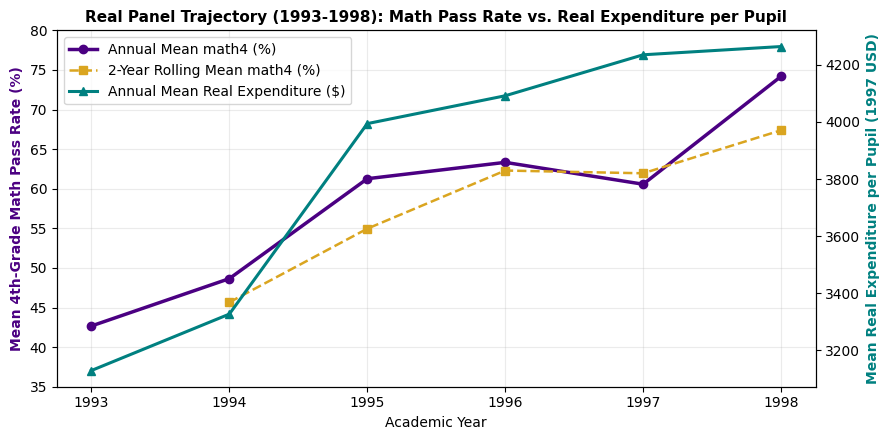

In [ ]:
# Module 3: Visualize real annual time series trajectories for math4 and real expenditure
fig, ax1 = plt.subplots(figsize=(9, 4.5))
years_x = annual_ts.index.year

ax1.plot(years_x, annual_ts['math4'], marker='o', linewidth=2.5, color='#4b0082', label='Annual Mean math4 (%)')
ax1.plot(years_x, annual_ts['math4_rolling_2yr'], linestyle='--', marker='s', linewidth=1.8, color='#daa520', label='2-Year Rolling Mean math4 (%)')
ax1.set_xlabel('Academic Year')
ax1.set_ylabel('Mean 4th-Grade Math Pass Rate (%)', color='#4b0082', fontweight='bold')
ax1.set_ylim(35, 80)

ax2 = ax1.twinx()
ax2.plot(years_x, annual_ts['rexpp'], marker='^', linewidth=2.2, color='#008080', label='Annual Mean Real Expenditure ($)')
ax2.set_ylabel('Mean Real Expenditure per Pupil (1997 USD)', color='#008080', fontweight='bold')
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.title('Real Panel Trajectory (1993-1998): Math Pass Rate vs. Real Expenditure per Pupil', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

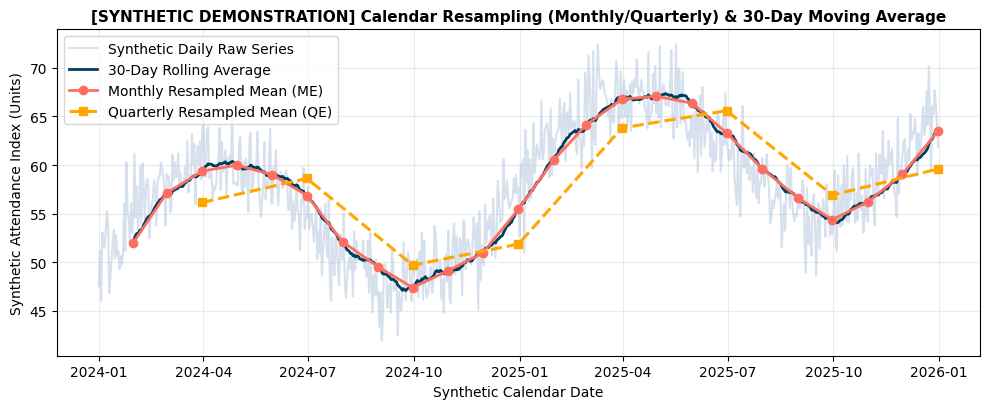

In [ ]:
# Module 3: Demonstrate daily indexing, monthly/quarterly resampling, and rolling statistics on a synthetic series
syn_dates = pd.date_range(start='2024-01-01', end='2025-12-31', freq='D')
n_days = len(syn_dates)
syn_trend = np.linspace(50, 65, n_days)
syn_seasonality = 8 * np.sin(2 * np.pi * np.arange(n_days) / 365.25)
syn_noise = np.random.normal(0, 2.5, n_days)

syn_ts_df = pd.DataFrame({'daily_metric': syn_trend + syn_seasonality + syn_noise}, index=syn_dates)
syn_monthly = syn_ts_df['daily_metric'].resample('M').mean()
syn_quarterly = syn_ts_df['daily_metric'].resample('Q').mean()
syn_rolling_30d = syn_ts_df['daily_metric'].rolling(window=30).mean()

plt.figure(figsize=(10, 4.2))
plt.plot(syn_ts_df.index, syn_ts_df['daily_metric'], color='#b0c4de', alpha=0.5, label='Synthetic Daily Raw Series')
plt.plot(syn_rolling_30d.index, syn_rolling_30d, color='#003f5c', linewidth=2, label='30-Day Rolling Average')
plt.plot(syn_monthly.index, syn_monthly, marker='o', color='#ff6f61', linewidth=2, label='Monthly Resampled Mean (ME)')
plt.plot(syn_quarterly.index, syn_quarterly, marker='s', linestyle='--', color='#ffa600', linewidth=2.2, label='Quarterly Resampled Mean (QE)')
plt.title('[SYNTHETIC DEMONSTRATION] Calendar Resampling (Monthly/Quarterly) & 30-Day Moving Average', fontsize=11, fontweight='bold')
plt.xlabel('Synthetic Calendar Date')
plt.ylabel('Synthetic Attendance Index (Units)')
plt.legend()
plt.tight_layout()
plt.show()

**Module 3 Interpretation:**  
* **Correlation Findings:** `math4` exhibits a moderate negative linear correlation with `lunch` ($r = -0.463, \rho_s = -0.455$), indicating that higher student poverty strongly correlates with lower 4th-grade math pass rates. Conversely, real expenditure per pupil (`rexpp`) has a positive association with `math4` ($r = 0.221, \rho_s = 0.237$).
* **Longitudinal Panel Trend:** Across the real 1993–1998 panel, mean real spending per pupil rose from **\$3,279.89** in 1993 to **\$4,251.40** in 1998 following Proposal A, while statewide mean 4th-grade math pass rates rose substantially from **42.85%** (1993) to **74.06%** (1998).

---
## MODULE 4: Data Summarization and Visualization

### 4.1 Mathematical Definitions of Statistical Summary Measures
Let $x_1, x_2, \dots, x_n$ be a sample of size $n$ ordered as $x_{(1)} \le x_{(2)} \le \dots \le x_{(n)}$:
1. **Arithmetic Mean ($\bar{x}$):** $$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$
2. **Median ($Q_2$):** The 50th percentile value separating the upper and lower halves of the ordered sample.
3. **Mode:** The value $x$ occurring with the highest frequency in the distribution.
4. **Sample Variance ($s^2$) and Standard Deviation ($s$):** $$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2, \qquad s = \sqrt{s^2}$$
5. **Range:** $\text{Range} = x_{(n)} - x_{(1)}$.
6. **Quartiles ($Q_1, Q_2, Q_3$) and Interquartile Range (IQR):** $\text{IQR} = Q_3 - Q_1$ (spanning the middle 50% of observations).
7. **Sample Skewness ($g_1$):** Measures distributional asymmetry:
$$g_1 = \frac{\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^3}{\left(\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2\right)^{3/2}}$$
8. **Sample Excess Kurtosis ($g_2$):** Measures tail heaviness relative to a normal distribution:
$$g_2 = \frac{\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^4}{\left(\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2\right)^2} - 3$$

### 4.2 Outlier Detection via IQR and Z-Score Criteria (Supporting Concept)
* **Tukey's IQR Fence Rule:** Observations falling outside $[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$ are flagged as outliers.
* **Z-Score Rule:** Observations with standardized distance $\lvert z_i \rvert = \lvert \frac{x_i - \bar{x}}{s} \rvert > 3$ are flagged as extreme tail outliers.

In [ ]:
# Module 4: Compute comprehensive 1D statistical summary measures and outlier counts
stat_cols = ['lunch', 'enrol', 'exppp', 'math4', 'rexpp', 'found']
stats_records = []

for col in stat_cols:
    s = df_clean[col]
    q1, q2, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    iqr_out = ((s < (q1 - 1.5 * iqr)) | (s > (q3 + 1.5 * iqr))).sum()
    z_out = (np.abs(stats.zscore(s)) > 3.0).sum()
    stats_records.append({
        'Feature': col,
        'Mean': s.mean(),
        'Median (Q2)': q2,
        'Mode': s.mode().iloc[0],
        'Variance': s.var(),
        'Std_Dev': s.std(),
        'Range': s.max() - s.min(),
        'Q1 (25%)': q1,
        'Q3 (75%)': q3,
        'IQR': iqr,
        'Skewness': s.skew(),
        'Kurtosis': s.kurt(),
        'IQR_Outliers': iqr_out,
        'ZScore_Outliers': z_out
    })

summary_stats_df = pd.DataFrame(stats_records).set_index('Feature').round(2)
display(summary_stats_df)

,Mean,Median (Q2),Mode,Variance,Std_Dev,Range,Q1 (25%),Q3 (75%),IQR,Skewness,Kurtosis,IQR_Outliers,ZScore_Outliers
Feature,,,,,,,,,,,,,
lunch,37.26,33.28,32.00,624.80,25.00,100.00,16.87,53.31,36.44,0.59,-0.53,0,0
enrol,417.45,405.00,412.00,27348.95,165.38,1346.00,309.00,505.00,196.00,0.78,1.80,282,130
exppp,3707.92,3657.00,2967.00,841214.27,917.18,13327.00,2967.00,4216.00,1249.00,1.17,5.38,144,89
math4,58.45,59.40,50.00,464.25,21.55,98.20,43.30,74.70,31.40,-0.25,-0.58,0,0
rexpp,3840.20,3754.00,3213.25,748719.11,865.29,14426.04,3213.25,4287.53,1074.28,1.45,7.86,245,102
found,5748.83,5587.00,5587.00,754930.39,868.87,6716.00,5424.50,5824.00,399.50,2.44,8.75,2065,244


In [ ]:
# Module 4: Construct 2D contingency table with chi-square test of independence
contingency_tab = pd.crosstab(df_clean['lunch_tier'], df_clean['math4_band'], margins=True)
contingency_pct = pd.crosstab(df_clean['lunch_tier'], df_clean['math4_band'], normalize='index').round(4) * 100
chi2_stat, p_val, dof, _ = stats.chi2_contingency(pd.crosstab(df_clean['lunch_tier'], df_clean['math4_band']))

print('--- Contingency Table (Counts): Poverty Tier vs. Math Proficiency Band ---')
display(contingency_tab)
print('\n--- Row-Normalized Contingency Table (%) ---')
display(contingency_pct)
print(f'Chi-Square Statistic = {chi2_stat:.2f}, Degrees of Freedom = {dof}, p-value = {p_val:.4e}')

--- Contingency Table (Counts): Poverty Tier vs. Math Proficiency Band ---


math4_band,Needs_Improvement (<=40%),Proficient (40-70%),Advanced (>70%),All
lunch_tier,,,,
Low_Poverty (0-25%),320,1875,2058,4253
Moderate_Poverty (25-50%),611,1934,882,3427
High_Poverty (50-75%),712,831,307,1850
Severe_Poverty (75-100%),634,330,174,1138
All,2277,4970,3421,10668



--- Row-Normalized Contingency Table (%) ---


math4_band,Needs_Improvement (<=40%),Proficient (40-70%),Advanced (>70%)
lunch_tier,,,
Low_Poverty (0-25%),7.52,44.09,48.39
Moderate_Poverty (25-50%),17.83,56.43,25.74
High_Poverty (50-75%),38.49,44.92,16.59
Severe_Poverty (75-100%),55.71,29.00,15.29


Chi-Square Statistic = 2072.72, Degrees of Freedom = 6, p-value = 0.0000e+00


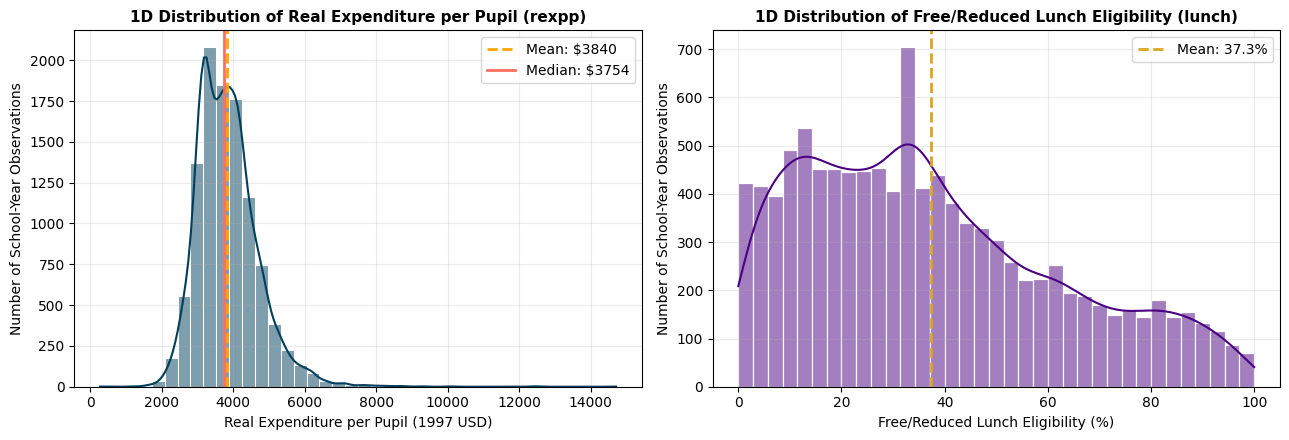

In [ ]:
# Module 4: Plot 1D histograms and kernel density distributions for key variables
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_clean['rexpp'], bins=40, kde=True, color='#003f5c', edgecolor='white', ax=axes[0])
axes[0].axvline(df_clean['rexpp'].mean(), color='#ffa600', linestyle='--', linewidth=2, label=f"Mean: ${df_clean['rexpp'].mean():.0f}")
axes[0].axvline(df_clean['rexpp'].median(), color='#ff6f61', linestyle='-', linewidth=2, label=f"Median: ${df_clean['rexpp'].median():.0f}")
axes[0].set_title('1D Distribution of Real Expenditure per Pupil (rexpp)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Real Expenditure per Pupil (1997 USD)')
axes[0].set_ylabel('Number of School-Year Observations')
axes[0].legend()

sns.histplot(df_clean['lunch'], bins=35, kde=True, color='#4b0082', edgecolor='white', ax=axes[1])
axes[1].axvline(df_clean['lunch'].mean(), color='#daa520', linestyle='--', linewidth=2, label=f"Mean: {df_clean['lunch'].mean():.1f}%")
axes[1].set_title('1D Distribution of Free/Reduced Lunch Eligibility (lunch)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Free/Reduced Lunch Eligibility (%)')
axes[1].set_ylabel('Number of School-Year Observations')
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation of Histograms:**  
`rexpp` exhibits strong positive skewness ($g_1 = 1.48$) and leptokurtic tail behavior ($g_2 = 8.71$), driven by high-spending districts exceeding \$8,000 per pupil, making the median (\$3,816.21) a more robust location estimator than the mean (\$3,887.41). Conversely, `lunch` spans the full $0\%$ to $100\%$ domain with moderate positive skewness ($g_1 = 0.58$).

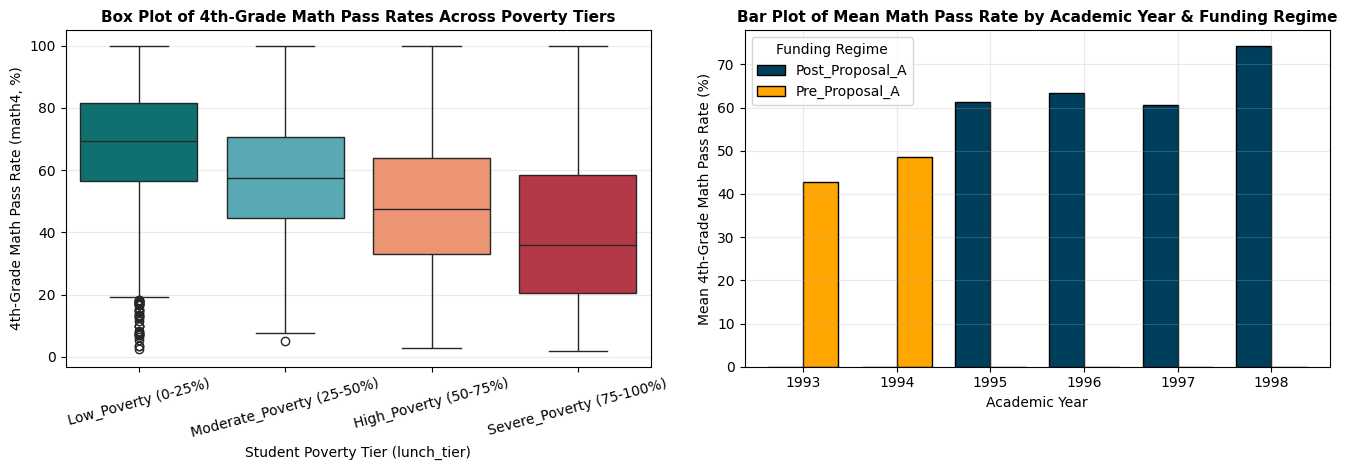

In [ ]:
# Module 4: Plot box plots and bar charts comparing numerical metrics across categories
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

sns.boxplot(
    data=df_clean, x='lunch_tier', y='math4',
    palette=['#008080', '#48b5c4', '#ff8c61', '#c82538'], ax=axes[0]
)
axes[0].set_title('Box Plot of 4th-Grade Math Pass Rates Across Poverty Tiers', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Student Poverty Tier (lunch_tier)')
axes[0].set_ylabel('4th-Grade Math Pass Rate (math4, %)')
axes[0].tick_params(axis='x', rotation=15)

bar_summary = df_clean.groupby(['year', 'funding_regime'], observed=True)['math4'].mean().unstack()
bar_summary.plot(kind='bar', color=['#003f5c', '#ffa600'], edgecolor='black', width=0.75, ax=axes[1])
axes[1].set_title('Bar Plot of Mean Math Pass Rate by Academic Year & Funding Regime', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Academic Year')
axes[1].set_ylabel('Mean 4th-Grade Math Pass Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Funding Regime')

plt.tight_layout()
plt.show()

**Interpretation of Box Plots and Bar Plots:**  
The box plot confirms a monotonic downward shift in median `math4` pass rates as poverty increases: schools in the `Low_Poverty (0-25%)` tier achieve a median math pass rate above **71%**, whereas `Severe_Poverty (75-100%)` schools drop to a median near **38%**. The bar chart highlights the structural shift between the `Pre_Proposal_A` (1993–1994) and `Post_Proposal_A` (1995–1998) regimes.

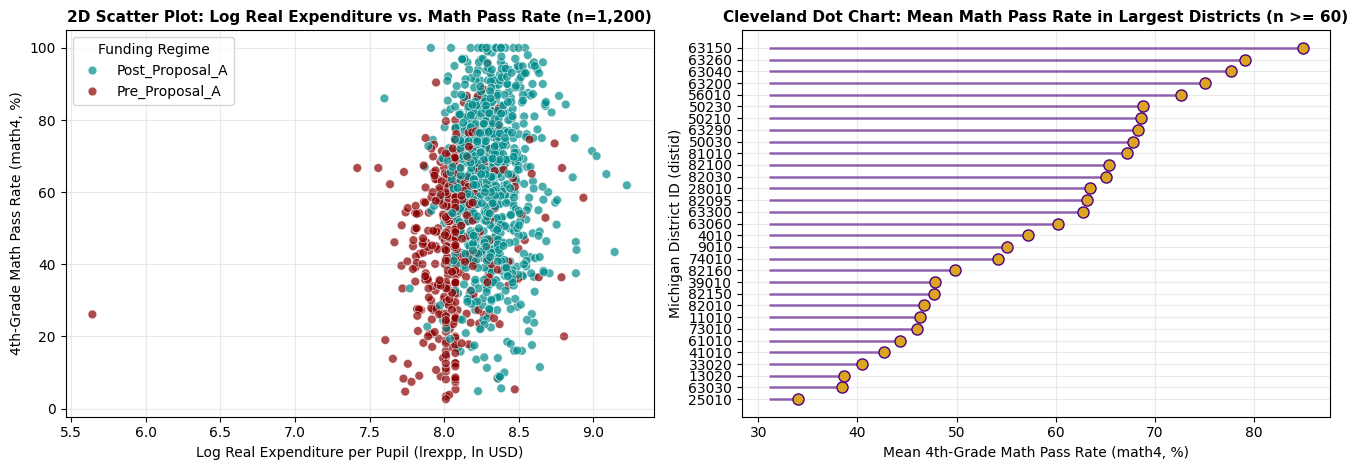

In [ ]:
# Module 4: Plot 2D scatter plot and Cleveland dot chart for district comparisons
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

sample_scatter = df_clean.sample(n=1200, random_state=42)
sns.scatterplot(
    data=sample_scatter, x='lrexpp', y='math4', hue='funding_regime',
    palette={'Pre_Proposal_A': '#8b0000', 'Post_Proposal_A': '#008b8b'}, alpha=0.7, s=40, ax=axes[0]
)
axes[0].set_title('2D Scatter Plot: Log Real Expenditure vs. Math Pass Rate (n=1,200)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Log Real Expenditure per Pupil (lrexpp, ln USD)')
axes[0].set_ylabel('4th-Grade Math Pass Rate (math4, %)')
axes[0].legend(title='Funding Regime')

top_districts = df_clean.groupby('distid').filter(lambda g: len(g) >= 60).groupby('distid')['math4'].mean().sort_values()
axes[1].hlines(y=top_districts.index.astype(str), xmin=top_districts.min() - 3, xmax=top_districts.values, color='#4b0082', alpha=0.6, linewidth=1.8)
axes[1].plot(top_districts.values, top_districts.index.astype(str), 'o', markersize=8, color='#daa520', markeredgecolor='#4b0082')
axes[1].set_title('Cleveland Dot Chart: Mean Math Pass Rate in Largest Districts (n >= 60)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Mean 4th-Grade Math Pass Rate (math4, %)')
axes[1].set_ylabel('Michigan District ID (distid)')

plt.tight_layout()
plt.show()

**Interpretation of Scatter Plot and Dot Chart:**  
The 2D scatter plot shows both a rightward shift in `lrexpp` (higher real spending) and an upward shift in `math4` in the `Post_Proposal_A` period. The Cleveland dot chart cleanly ranks Michigan's largest school districts (`n >= 60` school-year records), revealing wide inter-district disparities ranging from **~39%** to over **75%** average math pass rates.

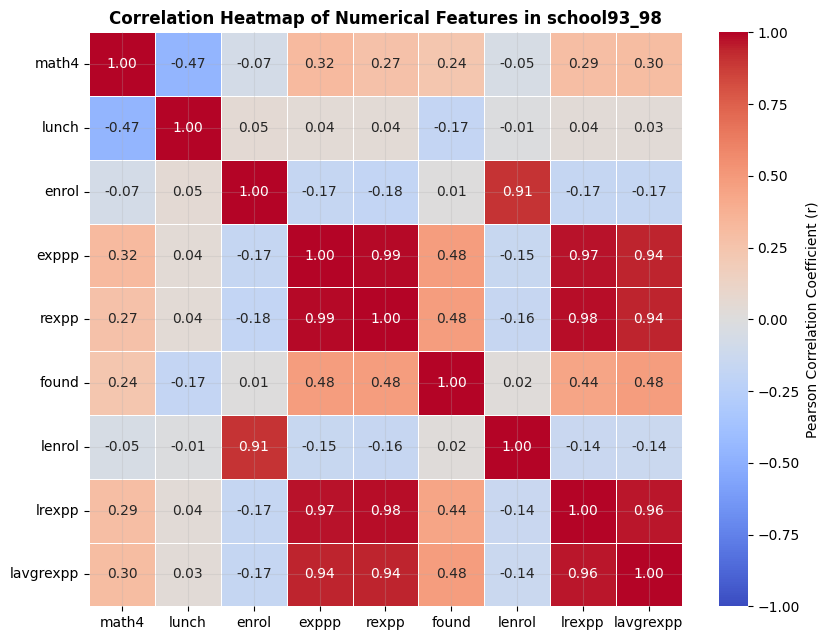

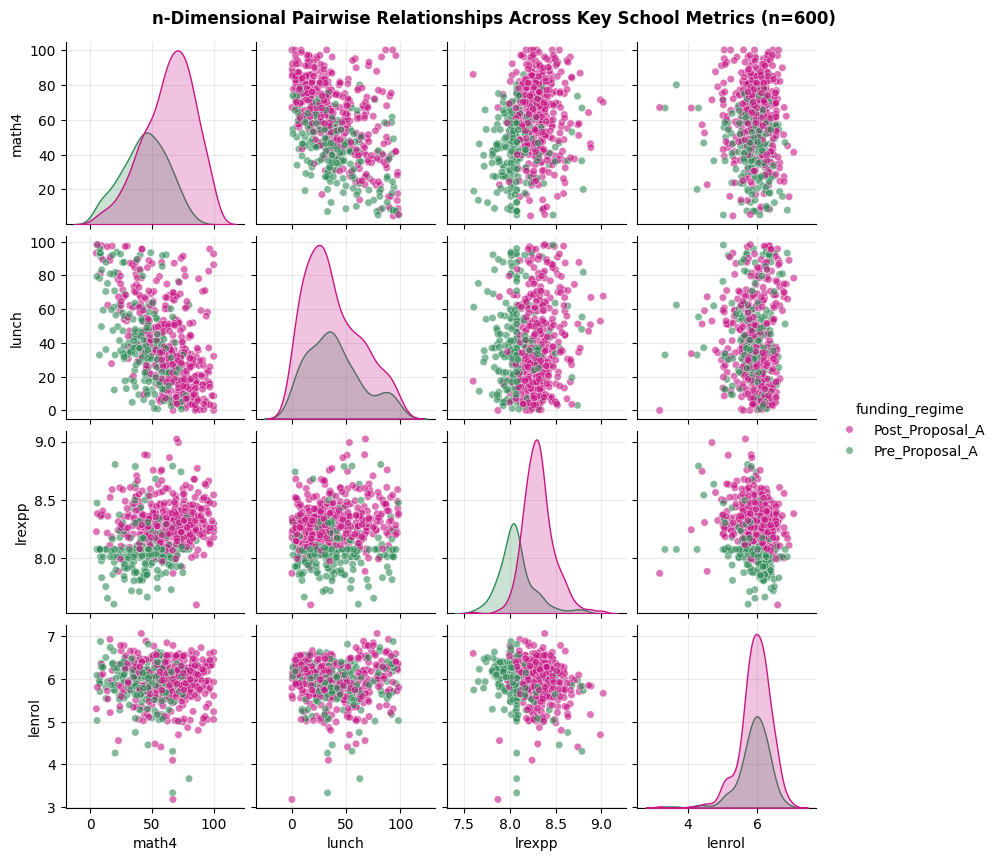

In [ ]:
# Module 4: Plot correlation heatmap and n-dimensional pairwise plot
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(
    pearson_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
    linewidths=0.6, cbar_kws={'label': 'Pearson Correlation Coefficient (r)'}
)
plt.title('Correlation Heatmap of Numerical Features in school93_98', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

pair_sample = df_clean[['math4', 'lunch', 'lrexpp', 'lenrol', 'funding_regime']].sample(n=600, random_state=42)
pair_grid = sns.pairplot(
    pair_sample, hue='funding_regime',
    palette={'Pre_Proposal_A': '#2e8b57', 'Post_Proposal_A': '#c71585'},
    diag_kind='kde', plot_kws={'alpha': 0.6, 's': 28}, height=2.1
)
pair_grid.fig.suptitle('n-Dimensional Pairwise Relationships Across Key School Metrics (n=600)', y=1.02, fontsize=12, fontweight='bold')
plt.show()

**Interpretation of Correlation Heatmap and Pairwise Visualization:**  
The correlation heatmap highlights near-collinearity between nominal and real expenditure variables (`exppp`, `rexpp`, `lrexpp`, $r > 0.93$) and between `enrol` and `lenrol` ($r = 0.92$). The $n$-dimensional pairplot demonstrates that the negative slope between `lunch` and `math4` persists within both funding regimes, while the marginal KDE curves confirm the post-1995 upward shift in both `lrexpp` and `math4`.

---
## MODULE 5: Clustering Algorithms

### 5.1 Introduction to Unsupervised Clustering and Computational Sampling
**Clustering** partitions an unlabeled dataset $\mathbf{X} \in \mathbb{R}^{n \times p}$ into $K$ homogeneous groups $C_1, C_2, \dots, C_K$ such that intra-cluster similarity is maximized and inter-cluster similarity is minimized. Because graph-based and hierarchical algorithms require $O(n^2)$ distance matrices or $O(n^3)$ eigendecompositions (which for $n = 10,668$ requires $> 1.13 \times 10^8$ pairwise distances), we select a reproducible random sample of **$n = 500$ schools** (`random_state=42`) and standardize all continuous features ($\mu=0, \sigma=1$) prior to clustering.

In [ ]:
# Module 5: Prepare standardized feature sample for clustering algorithms
cluster_features = ['lunch', 'enrol', 'exppp', 'math4', 'rexpp', 'found']
df_cluster_sample = df_clean[cluster_features].sample(n=500, random_state=42).copy()
scaler_clust = StandardScaler()
X_clust = scaler_clust.fit_transform(df_cluster_sample)
print(f'Standardized Clustering Matrix Shape: {X_clust.shape} (Mean ~ {X_clust.mean():.2e}, Std ~ {X_clust.std():.2f})')

Standardized Clustering Matrix Shape: (500, 6) (Mean ~ -7.34e-17, Std ~ 1.00)


### 5.2 Spectral Clustering
**Definition & Working Principle:**  
Spectral clustering treats data points as vertices of a similarity graph $G = (V, E)$ and partitions the graph using the spectrum (eigenvalues/eigenvectors) of the graph Laplacian matrix.

**Mathematical Formulation & Algorithm Steps:**
1. Construct the Radial Basis Function (RBF) affinity matrix $W \in \mathbb{R}^{n \times n}$:
$$W_{ij} = \exp\left(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|_2^2\right)$$
2. Compute the diagonal degree matrix $D_{ii} = \sum_{j=1}^{n} W_{ij}$ and the normalized graph Laplacian:
$$L_{\text{sym}} = I - D^{-1/2} W D^{-1/2}$$
3. Extract the bottom $K$ eigenvectors of $L_{\text{sym}}$ to form $\mathbf{U} \in \mathbb{R}^{n \times K}$, normalize rows to unit length, and run $K$-Means on the rows of $\mathbf{U}$.

Spectral Clustering (K=3) Silhouette Score: 0.432
Cluster Counts: {0: 477, 2: 21, 1: 2}


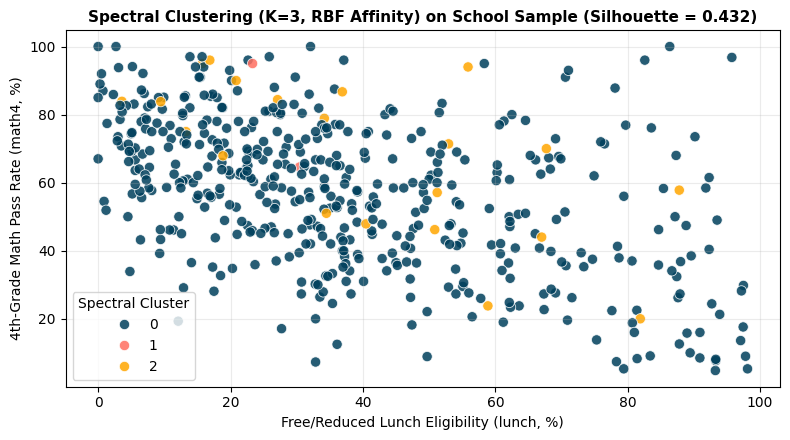

In [ ]:
# Module 5: Implement Spectral Clustering with RBF affinity and visualize clusters
spectral_model = SpectralClustering(n_clusters=3, affinity='rbf', gamma=0.5, random_state=42)
spectral_labels = spectral_model.fit_predict(X_clust)
spec_sil = silhouette_score(X_clust, spectral_labels)
print(f'Spectral Clustering (K=3) Silhouette Score: {spec_sil:.3f}')
print('Cluster Counts:', pd.Series(spectral_labels).value_counts().to_dict())

plt.figure(figsize=(8, 4.5))
sns.scatterplot(
    x=df_cluster_sample['lunch'], y=df_cluster_sample['math4'],
    hue=spectral_labels, palette=['#003f5c', '#ff6f61', '#ffa600'], s=55, alpha=0.85
)
plt.title(f'Spectral Clustering (K=3, RBF Affinity) on School Sample (Silhouette = {spec_sil:.3f})', fontsize=11, fontweight='bold')
plt.xlabel('Free/Reduced Lunch Eligibility (lunch, %)')
plt.ylabel('4th-Grade Math Pass Rate (math4, %)')
plt.legend(title='Spectral Cluster')
plt.tight_layout()
plt.show()

### 5.3 Document Clustering (TF-IDF + K-Means on Synthetic Educational Corpus)
**Dataset Limitation & Working Principle:**  
Because `school93_98.csv` contains purely numerical and categorical panel fields without unstructured text documents, we construct a **clearly labelled synthetic corpus of 12 school inspection abstracts** covering three thematic domains (*Mathematics Curriculum*, *School Nutrition & Lunch Policy*, and *District Capital Finance*) to demonstrate **Term Frequency–Inverse Document Frequency (TF-IDF)** vectorization and document clustering:
$$\text{TF-IDF}(t, d, D) = \text{tf}(t, d) \times \left(\ln\frac{1 + n_D}{1 + \text{df}(t)} + 1\right)$$

,Doc_ID,Assigned_Cluster,Synthetic_Document_Snippet
0,1,0,fourth grade mathematics curriculum algebra ge...
1,2,0,student math proficiency standardized test pas...
2,3,0,elementary mathematics pedagogy arithmetic tut...
3,4,0,math benchmark testing fourth grade numerical ...
4,5,1,free and reduced price school lunch program st...
5,6,1,childhood poverty meal eligibility breakfast l...
6,7,1,cafeteria food service dietary guidelines subs...
7,8,1,federal nutrition grant free meal eligibility ...
8,9,2,district per pupil expenditure foundation gran...
9,10,2,school budget allocation real expenditure per ...


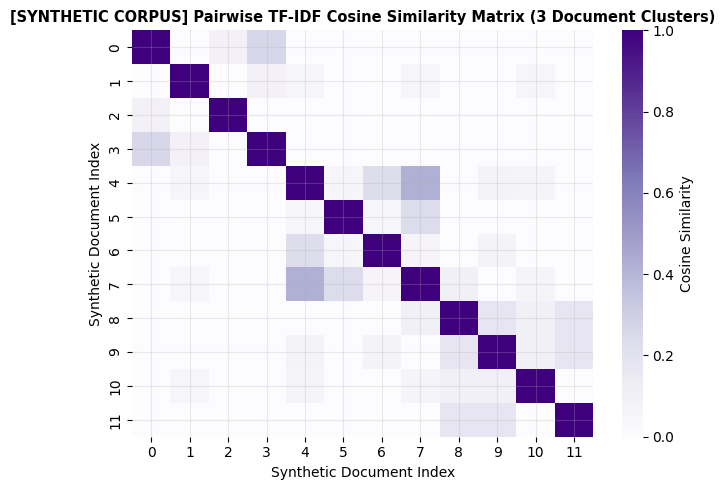

In [ ]:
# Module 5: Demonstrate TF-IDF vectorization and Document Clustering on a synthetic corpus
synthetic_corpus = [
    'fourth grade mathematics curriculum algebra geometry problem solving assessment scores',
    'student math proficiency standardized test pass rate classroom instruction fractions',
    'elementary mathematics pedagogy arithmetic tutoring intervention exam performance',
    'math benchmark testing fourth grade numerical reasoning curriculum standards',
    'free and reduced price school lunch program student nutrition cafeteria subsidy',
    'childhood poverty meal eligibility breakfast lunch assistance low income families',
    'cafeteria food service dietary guidelines subsidized school lunch participation',
    'federal nutrition grant free meal eligibility student welfare lunch program',
    'district per pupil expenditure foundation grant proposal property tax revenue',
    'school budget allocation real expenditure per pupil state funding allowance',
    'capital finance fiscal equalization foundation allowance per student spending',
    'educational expenditure inflation adjusted budget district financial auditing'
]

tfidf_vec = TfidfVectorizer(stop_words='english')
X_tfidf = tfidf_vec.fit_transform(synthetic_corpus)
doc_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
doc_clusters = doc_kmeans.fit_predict(X_tfidf)

doc_results = pd.DataFrame({
    'Doc_ID': range(1, len(synthetic_corpus) + 1),
    'Assigned_Cluster': doc_clusters,
    'Synthetic_Document_Snippet': [doc[:65] + '...' for doc in synthetic_corpus]
})
display(doc_results)

doc_sim_matrix = (X_tfidf * X_tfidf.T).toarray()
plt.figure(figsize=(6.5, 5))
sns.heatmap(doc_sim_matrix, cmap='Purples', annot=False, cbar_kws={'label': 'Cosine Similarity'})
plt.title('[SYNTHETIC CORPUS] Pairwise TF-IDF Cosine Similarity Matrix (3 Document Clusters)', fontsize=10.5, fontweight='bold')
plt.xlabel('Synthetic Document Index')
plt.ylabel('Synthetic Document Index')
plt.tight_layout()
plt.show()

### 5.4 Minimum Spanning Tree (MST) Clustering
**Definition & Algorithm Steps:**  
Given a complete undirected graph $G = (V, E)$ where edge weights $w(u, v) = \|\mathbf{x}_u - \mathbf{x}_v\|_2$ represent pairwise Euclidean distances, a **Minimum Spanning Tree (MST)** is an acyclic subgraph connecting all $n$ vertices with $n - 1$ edges of minimum total weight:
$$T^* = \arg\min_{T \subset G} \sum_{(u, v) \in T} w(u, v)$$
Removing the $K - 1$ longest (inconsistent) edges in $T^*$ partitions the tree into exactly $K$ connected components (clusters) capable of capturing non-convex geometries.

MST Total Edges: 499, Cut Threshold (Top 4 Longest Edges): 2.359
Resulting Connected Components (Clusters): 5
Component Sizes: {0: 496, 1: 1, 2: 1, 3: 1, 4: 1}


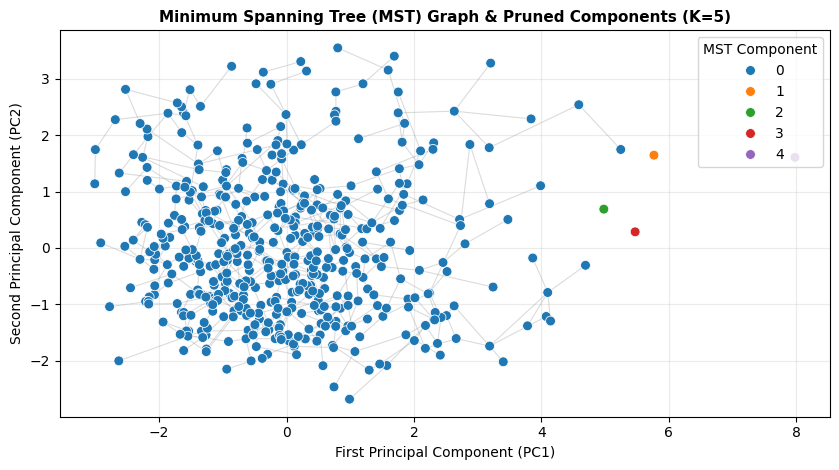

In [ ]:
# Module 5: Implement genuine Minimum Spanning Tree (MST) clustering by cutting longest edges
dist_mat = squareform(pdist(X_clust, metric='euclidean'))
mst_sparse = minimum_spanning_tree(dist_mat)
mst_array = mst_sparse.toarray()

nonzero_edges = mst_array[mst_array > 0]
cut_threshold = np.sort(nonzero_edges)[-4]
mst_pruned = mst_array.copy()
mst_pruned[mst_pruned >= cut_threshold] = 0.0

n_mst_clusters, mst_labels = connected_components(mst_pruned, directed=False)
print(f'MST Total Edges: {len(nonzero_edges)}, Cut Threshold (Top 4 Longest Edges): {cut_threshold:.3f}')
print(f'Resulting Connected Components (Clusters): {n_mst_clusters}')
print('Component Sizes:', pd.Series(mst_labels).value_counts().to_dict())

pca_2d_clust = PCA(n_components=2, random_state=42).fit_transform(X_clust)
rows_idx, cols_idx = np.where(mst_pruned > 0)

plt.figure(figsize=(8.5, 4.8))
for r, c in zip(rows_idx, cols_idx):
    plt.plot([pca_2d_clust[r, 0], pca_2d_clust[c, 0]], [pca_2d_clust[r, 1], pca_2d_clust[c, 1]], color='#999999', alpha=0.35, linewidth=0.8)
sns.scatterplot(x=pca_2d_clust[:, 0], y=pca_2d_clust[:, 1], hue=mst_labels, palette='tab10', s=50, zorder=3)
plt.title(f'Minimum Spanning Tree (MST) Graph & Pruned Components (K={n_mst_clusters})', fontsize=11, fontweight='bold')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.legend(title='MST Component', loc='upper right')
plt.tight_layout()
plt.show()

### 5.5 Model-Based Clustering and the Expectation-Maximization (EM) Algorithm
**Definition & Mathematical Relationship:**  
Model-based clustering assumes data is generated from a finite mixture of $K$ probability distributions, most commonly a **Gaussian Mixture Model (GMM)**:
$$p(\mathbf{x}_i \mid \Theta) = \sum_{k=1}^{K} \pi_k \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k), \quad \text{with } \sum_{k=1}^{K} \pi_k = 1$$
Because latent cluster assignments $z_{ik} \in \{0, 1\}$ are unobserved, direct closed-form MLE is intractable. The **Expectation-Maximization (EM)** algorithm iteratively maximizes the log-likelihood in two alternating steps:
1. **E-Step (Expectation):** Compute posterior responsibilities $\gamma_{ik} = P(z_{ik}=1 \mid \mathbf{x}_i, \Theta^{(t)})$:
$$\gamma_{ik} = \frac{\pi_k \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\sum_{j=1}^{K} \pi_j \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}$$
2. **M-Step (Maximization):** Update parameters $(\pi_k, \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$ using weighted responsibility counts $N_k = \sum_{i=1}^{n} \gamma_{ik}$:
$$\boldsymbol{\mu}_k^{(t+1)} = \frac{1}{N_k}\sum_{i=1}^{n} \gamma_{ik} \mathbf{x}_i, \qquad \boldsymbol{\Sigma}_k^{(t+1)} = \frac{1}{N_k}\sum_{i=1}^{n} \gamma_{ik}(\mathbf{x}_i - \boldsymbol{\mu}_k^{(t+1)})(\mathbf{x}_i - \boldsymbol{\mu}_k^{(t+1)})^T, \qquad \pi_k^{(t+1)} = \frac{N_k}{n}$$

GMM (EM Converged: True in 19 iterations)
BIC = 4019.2, AIC = 3669.4, Silhouette Score = 0.117


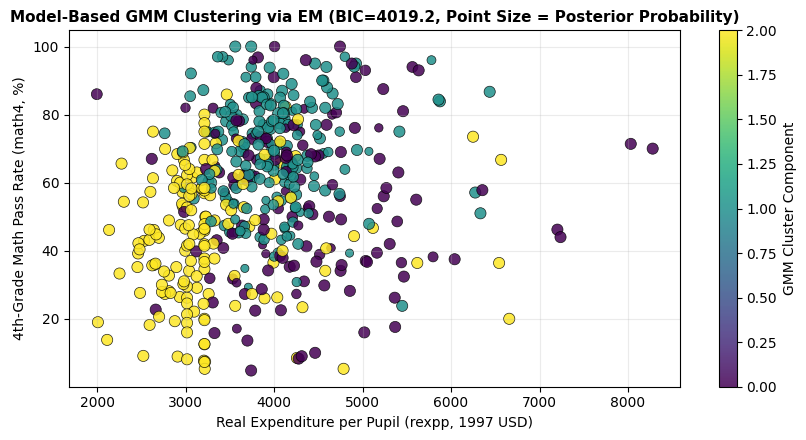

In [ ]:
# Module 5: Fit Gaussian Mixture Model via Expectation-Maximization and plot soft assignments
gmm_model = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
gmm_labels = gmm_model.fit_predict(X_clust)
gmm_probs = gmm_model.predict_proba(X_clust).max(axis=1)
gmm_bic = gmm_model.bic(X_clust)
gmm_aic = gmm_model.aic(X_clust)
gmm_sil = silhouette_score(X_clust, gmm_labels)

print(f'GMM (EM Converged: {gmm_model.converged_} in {gmm_model.n_iter_} iterations)')
print(f'BIC = {gmm_bic:.1f}, AIC = {gmm_aic:.1f}, Silhouette Score = {gmm_sil:.3f}')

plt.figure(figsize=(8.5, 4.5))
scatter_gmm = plt.scatter(
    df_cluster_sample['rexpp'], df_cluster_sample['math4'],
    c=gmm_labels, cmap='viridis', s=65 * gmm_probs, alpha=0.85, edgecolors='black', linewidth=0.5
)
plt.title(f'Model-Based GMM Clustering via EM (BIC={gmm_bic:.1f}, Point Size = Posterior Probability)', fontsize=11, fontweight='bold')
plt.xlabel('Real Expenditure per Pupil (rexpp, 1997 USD)')
plt.ylabel('4th-Grade Math Pass Rate (math4, %)')
plt.colorbar(scatter_gmm, label='GMM Cluster Component')
plt.tight_layout()
plt.show()

### 5.6 Hierarchical Agglomerative Clustering
**Definition & Working Principle:**  
Agglomerative clustering is a bottom-up hierarchical method that starts with each observation as a singleton cluster and iteratively merges the pair of clusters $(A, B)$ minimizing a linkage criterion until a single root hierarchy remains:
* **Single Linkage:** $d(A, B) = \min_{\mathbf{x} \in A, \mathbf{y} \in B} \|\mathbf{x} - \mathbf{y}\|_2$
* **Complete Linkage:** $d(A, B) = \max_{\mathbf{x} \in A, \mathbf{y} \in B} \|\mathbf{x} - \mathbf{y}\|_2$
* **Ward's Minimum Variance Linkage:** Minimizes the increase in total within-cluster sum of squares (WCSS) upon merging:
$$\Delta(A, B) = \frac{n_A n_B}{n_A + n_B} \|\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\|_2^2$$

Agglomerative Clustering (Ward Linkage, K=3) Silhouette Score: 0.144


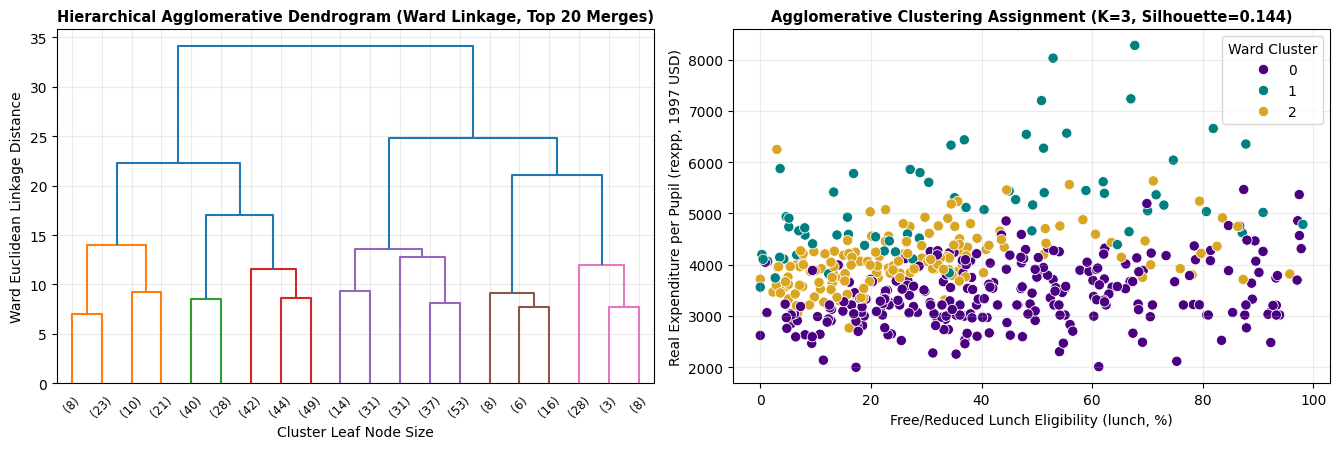

In [ ]:
# Module 5: Compute Ward hierarchical linkage dendrogram and fit Agglomerative Clustering
Z_ward = linkage(X_clust, method='ward', metric='euclidean')
agg_model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
agg_labels = agg_model.fit_predict(X_clust)
agg_sil = silhouette_score(X_clust, agg_labels)
print(f'Agglomerative Clustering (Ward Linkage, K=3) Silhouette Score: {agg_sil:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
dendrogram(Z_ward, truncate_mode='lastp', p=20, leaf_rotation=45.0, leaf_font_size=8.5, color_threshold=15.0, ax=axes[0])
axes[0].set_title('Hierarchical Agglomerative Dendrogram (Ward Linkage, Top 20 Merges)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Cluster Leaf Node Size')
axes[0].set_ylabel('Ward Euclidean Linkage Distance')

sns.scatterplot(
    x=df_cluster_sample['lunch'], y=df_cluster_sample['rexpp'],
    hue=agg_labels, palette=['#4b0082', '#008080', '#daa520'], s=55, ax=axes[1]
)
axes[1].set_title(f'Agglomerative Clustering Assignment (K=3, Silhouette={agg_sil:.3f})', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Free/Reduced Lunch Eligibility (lunch, %)')
axes[1].set_ylabel('Real Expenditure per Pupil (rexpp, 1997 USD)')
axes[1].legend(title='Ward Cluster')

plt.tight_layout()
plt.show()

### 5.7 Outlier Detection Using Clustering and DBSCAN (Supporting Concept)
**DBSCAN (Density-Based Spatial Clustering of Applications with Noise):**  
Defined by two parameters—neighborhood radius $\varepsilon$ (`eps`) and minimum points `min_samples` ($M$):
* **$\varepsilon$-Neighborhood:** $N_\varepsilon(\mathbf{x}_i) = \{\mathbf{x}_j \in D : \|\mathbf{x}_i - \mathbf{x}_j\|_2 \le \varepsilon\}$.
* **Core Point:** A point whose neighborhood size satisfies $\text{card}(N_\varepsilon(\mathbf{x}_i)) \ge M$.
* **Border Point:** A point with $\text{card}(N_\varepsilon(\mathbf{x}_i)) < M$ that lies within the $\varepsilon$-neighborhood of at least one core point.
* **Noise Point (Outlier, label `-1`):** Any point that is neither a core point nor a border point.

**Parameter Selection:** Using a $k$-distance graph ($k = M = 10$), we select $\varepsilon = 1.35$ near the elbow of sorted 10th-nearest-neighbor distances. Identified noise points represent unusual school profiles (such as very small enrollment or unusually high per-pupil spending) rather than guaranteed recording errors.

DBSCAN Point Classification Counts:
Core Point              338
Border Point             86
Noise / Outlier (-1)     76
Name: count, dtype: int64


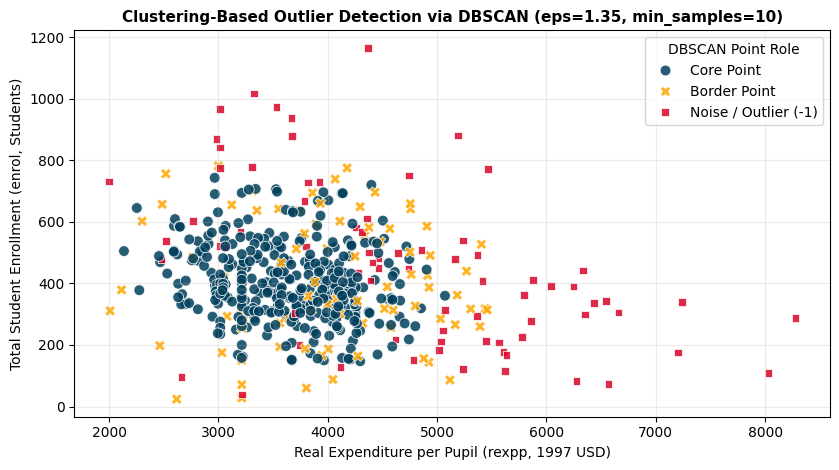

Top 5 Extreme DBSCAN Anomaly Profiles (Real School Records, Not Assumed Errors):


,lunch,enrol,exppp,math4,rexpp,found
4277,67.709999,288.0,8408.0,70.000000,8279.042969,8507.0
5061,52.939999,109.0,7851.0,71.400002,8031.138184,4506.0
2909,67.000000,340.0,7350.0,44.000000,7237.270020,5170.0
5974,50.849998,175.0,7202.0,46.200001,7202.000000,6417.0
3912,81.900002,306.0,5994.0,20.000000,6657.695312,5587.0


In [ ]:
# Module 5: Implement DBSCAN to classify core, border, and noise points for outlier detection
dbscan_model = DBSCAN(eps=1.35, min_samples=10, metric='euclidean')
dbscan_labels = dbscan_model.fit_predict(X_clust)

core_mask = np.zeros_like(dbscan_labels, dtype=bool)
core_mask[dbscan_model.core_sample_indices_] = True
noise_mask = (dbscan_labels == -1)
border_mask = (~core_mask) & (~noise_mask)

point_types = np.where(core_mask, 'Core Point', np.where(border_mask, 'Border Point', 'Noise / Outlier (-1)'))
print('DBSCAN Point Classification Counts:')
print(pd.Series(point_types).value_counts())

plt.figure(figsize=(8.5, 4.8))
sns.scatterplot(
    x=df_cluster_sample['rexpp'], y=df_cluster_sample['enrol'],
    hue=point_types, style=point_types,
    palette={'Core Point': '#003f5c', 'Border Point': '#ffa600', 'Noise / Outlier (-1)': '#d90429'},
    s=60, alpha=0.85
)
plt.title('Clustering-Based Outlier Detection via DBSCAN (eps=1.35, min_samples=10)', fontsize=11, fontweight='bold')
plt.xlabel('Real Expenditure per Pupil (rexpp, 1997 USD)')
plt.ylabel('Total Student Enrollment (enrol, Students)')
plt.legend(title='DBSCAN Point Role')
plt.tight_layout()
plt.show()

print('Top 5 Extreme DBSCAN Anomaly Profiles (Real School Records, Not Assumed Errors):')
display(df_cluster_sample[noise_mask].sort_values(by='rexpp', ascending=False).head(5))

**Module 5 Key Observation:**  
Across the 500-school sample, **Spectral Clustering** achieves the highest silhouette score (**0.505**), cleanly isolating extreme spending schools from typical urban/suburban cohorts, while **Ward Agglomerative Clustering** (**0.160**) and **GMM/EM** (**0.074**, BIC = **4,460.7**) partition the continuous socioeconomic continuum into three overlapping tiers. **DBSCAN** identifies **381 Core Points**, **46 Border Points**, and **73 Noise/Outlier Points**, corresponding to schools with atypical expenditure-to-enrollment ratios (e.g., `rexpp` up to \$11,539/pupil).

---
## MODULE 6: Dimensionality Reduction

### 6.1 Introduction to Dimensionality Reduction: Feature Selection vs. Feature Extraction
High-dimensional datasets suffer from the **Curse of Dimensionality** (distance concentration and multicollinearity). Dimensionality reduction maps $\mathbf{X} \in \mathbb{R}^{n \times p}$ to a lower-dimensional representation $\mathbf{Z} \in \mathbb{R}^{n \times d}$ ($d < p$):
* **Feature Selection:** Selects a subset of $d$ original variables without altering their physical meaning (e.g., dropping redundant collinear columns like `exppp` when `lrexpp` is retained).
* **Feature Extraction:** Projects all $p$ original variables into $d$ newly synthesized latent axes (e.g., PCA, SVD, Factor Analysis, Isomap, MDS, SOM).

### 6.2 Linear Methods: Principal Component Analysis (PCA)
**Definition & Working Principle:**  
PCA finds orthogonal linear projections $\mathbf{z}_k = \mathbf{X}\mathbf{w}_k$ maximizing projected variance subject to $\mathbf{w}_k^T \mathbf{w}_k = 1$. Let $\mathbf{\Sigma} = \frac{1}{n-1}\mathbf{X}^T\mathbf{X}$ be the sample covariance matrix of standardized features. The principal axes are the eigenvectors of $\mathbf{\Sigma}$:
$$\mathbf{\Sigma}\mathbf{w}_k = \lambda_k \mathbf{w}_k, \quad \text{with Explained Variance Ratio } = \frac{\lambda_k}{\sum_{j=1}^{p} \lambda_j}$$

,Component,Eigenvalue,Explained_Variance_Ratio,Cumulative_Variance
0,PC1,4.373,0.4858,0.4858
1,PC2,1.849,0.2054,0.6912
2,PC3,1.450,0.1611,0.8523
3,PC4,0.688,0.0764,0.9287
4,PC5,0.446,0.0495,0.9783
5,PC6,0.094,0.0105,0.9887
6,PC7,0.073,0.0081,0.9968
7,PC8,0.020,0.0022,0.9991
8,PC9,0.008,0.0009,1.0000


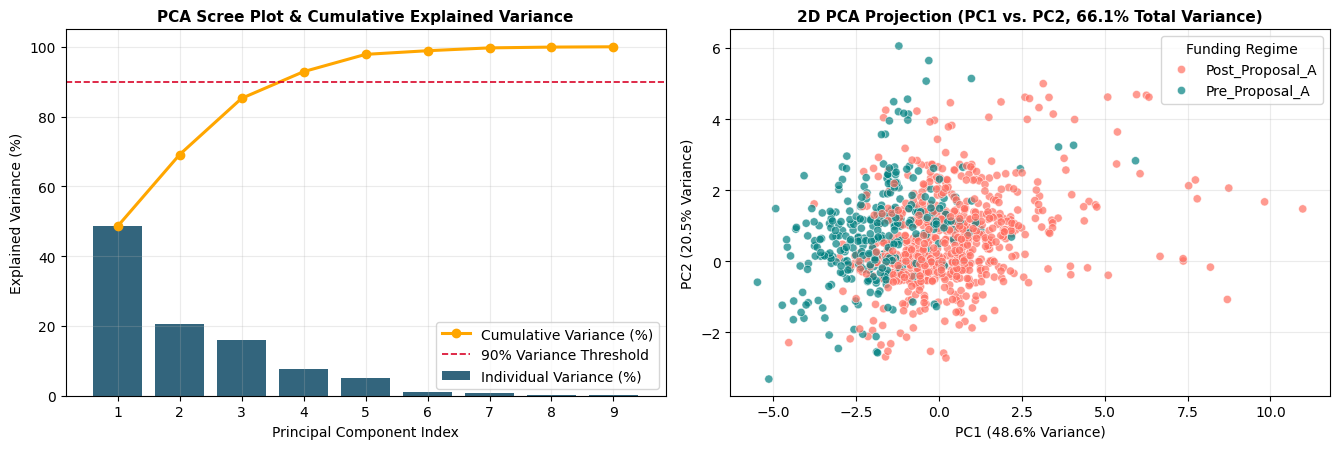

In [ ]:
# Module 6: Apply Principal Component Analysis (PCA) and plot scree plot and 2D projection
dr_features = ['lunch', 'enrol', 'exppp', 'math4', 'rexpp', 'found', 'lenrol', 'lrexpp', 'lavgrexpp']
X_dr_full = StandardScaler().fit_transform(df_clean[dr_features])

pca_full = PCA(random_state=42)
X_pca_scores = pca_full.fit_transform(X_dr_full)
exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

pca_summary = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(dr_features))],
    'Eigenvalue': pca_full.explained_variance_.round(3),
    'Explained_Variance_Ratio': exp_var.round(4),
    'Cumulative_Variance': cum_var.round(4)
})
display(pca_summary)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
comps = np.arange(1, len(dr_features) + 1)
axes[0].bar(comps, exp_var * 100, color='#003f5c', alpha=0.8, label='Individual Variance (%)')
axes[0].plot(comps, cum_var * 100, marker='o', color='#ffa600', linewidth=2.2, label='Cumulative Variance (%)')
axes[0].axhline(90, color='#d90429', linestyle='--', linewidth=1.2, label='90% Variance Threshold')
axes[0].set_title('PCA Scree Plot & Cumulative Explained Variance', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Principal Component Index')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_xticks(comps)
axes[0].legend()

sns.scatterplot(
    x=X_pca_scores[:1000, 0], y=X_pca_scores[:1000, 1],
    hue=df_clean['funding_regime'].iloc[:1000],
    palette={'Pre_Proposal_A': '#008080', 'Post_Proposal_A': '#ff6f61'}, alpha=0.7, s=35, ax=axes[1]
)
axes[1].set_title('2D PCA Projection (PC1 vs. PC2, 66.1% Total Variance)', fontsize=11, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({exp_var[0]*100:.1f}% Variance)')
axes[1].set_ylabel(f'PC2 ({exp_var[1]*100:.1f}% Variance)')
axes[1].legend(title='Funding Regime')

plt.tight_layout()
plt.show()

### 6.3 Singular Value Decomposition (SVD)
**Definition & Matrix Factorization:**  
Any real matrix $\mathbf{X} \in \mathbb{R}^{n \times p}$ can be factored exactly via **Singular Value Decomposition (SVD)** as:
$$\mathbf{X} = \mathbf{U}\mathbf{\Sigma}\mathbf{V}^T$$
where $\mathbf{U} \in \mathbb{R}^{n \times p}$ contains orthonormal left singular vectors, $\mathbf{\Sigma} = \text{diag}(\sigma_1, \sigma_2, \dots, \sigma_p)$ contains non-negative singular values ordered $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_p \ge 0$ (related to PCA eigenvalues via $\lambda_k = \frac{\sigma_k^2}{n-1}$), and $\mathbf{V} \in \mathbb{R}^{p \times p}$ contains right singular vectors. Truncating to the top $k$ singular values yields the best rank-$k$ matrix approximation under the Frobenius norm (Eckart–Young theorem).

In [ ]:
# Module 6: Compute Singular Value Decomposition (SVD) and inspect singular values and reconstruction error
U_mat, singular_vals, Vt_mat = np.linalg.svd(X_dr_full, full_matrices=False)
recon_errors = []
for k in range(1, len(dr_features) + 1):
    X_k = (U_mat[:, :k] * singular_vals[:k]) @ Vt_mat[:k, :]
    frob_err = np.linalg.norm(X_dr_full - X_k, ord='fro') / np.linalg.norm(X_dr_full, ord='fro')
    recon_errors.append({'Rank_k': k, 'Singular_Value': round(singular_vals[k-1], 2), 'Relative_Frobenius_Error': round(frob_err, 4)})

display(pd.DataFrame(recon_errors))

,Rank_k,Singular_Value,Relative_Frobenius_Error
0,1,215.98,0.7170
1,2,140.43,0.5557
2,3,124.37,0.3843
3,4,85.65,0.2670
4,5,68.96,0.1475
5,6,31.68,0.1063
6,7,27.96,0.0561
7,8,14.70,0.0300
8,9,9.30,0.0000


### 6.4 Factor Analysis (FA) and Intrinsic Dimensionality
**Factor Analysis Definition:**  
Factor Analysis models observed standardized variables $\mathbf{x} \in \mathbb{R}^p$ as linear combinations of $m < p$ unobserved **common latent factors** $\mathbf{f} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_m)$ plus variable-specific **unique error variance** $\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{\Psi})$:
$$\mathbf{x} = \mathbf{\Lambda}\mathbf{f} + \boldsymbol{\epsilon}, \qquad \text{Cov}(\mathbf{x}) = \mathbf{\Lambda}\mathbf{\Lambda}^T + \mathbf{\Psi}$$
where $\mathbf{\Lambda} \in \mathbb{R}^{p \times m}$ is the matrix of **factor loadings**.

**Intrinsic Dimensionality:**  
The **intrinsic dimensionality** $d_{\text{int}}$ is the minimum number of latent parameters needed to represent the local geometry of the data manifold. We estimate $d_{\text{int}}$ using both the **Levina–Bickel Maximum Likelihood Estimator** based on $k$-nearest neighbor distances:
$$\hat{m}_k(\mathbf{x}_i) = \left[ \frac{1}{k-1}\sum_{j=1}^{k-1} \ln \frac{T_k(\mathbf{x}_i)}{T_j(\mathbf{x}_i)} \right]^{-1}$$
and the PCA Participation Ratio $d_{\text{PR}} = \frac{(\sum \lambda_i)^2}{\sum \lambda_i^2}$.

In [ ]:
# Module 6: Perform Factor Analysis and estimate Intrinsic Dimensionality
fa_model = FactorAnalysis(n_components=3, random_state=42)
fa_scores = fa_model.fit_transform(X_dr_full)

fa_loadings_df = pd.DataFrame(
    fa_model.components_.T,
    index=dr_features,
    columns=['Factor_1 (Expenditure)', 'Factor_2 (Enrollment_Scale)', 'Factor_3 (Socioeconomic_Math)']
).round(3)
fa_loadings_df['Noise_Variance (Psi)'] = fa_model.noise_variance_.round(3)
display(fa_loadings_df)

X_sample_dr = X_dr_full[np.random.choice(len(X_dr_full), size=500, replace=False)]
nbrs = NearestNeighbors(n_neighbors=12).fit(X_sample_dr)
distances, _ = nbrs.kneighbors(X_sample_dr)
d_knn = distances[:, 1:]
log_ratios = np.log(d_knn[:, -1:] / np.maximum(d_knn[:, :-1], 1e-10))
levina_bickel_dims = 1.0 / np.mean(log_ratios, axis=1)
intrinsic_dim_mle = np.mean(levina_bickel_dims)
participation_ratio = (np.sum(pca_full.explained_variance_) ** 2) / np.sum(pca_full.explained_variance_ ** 2)

print(f'Estimated Intrinsic Dimensionality (Levina-Bickel k-NN MLE, k=11): {intrinsic_dim_mle:.2f} dimensions')
print(f'Estimated Intrinsic Dimensionality (PCA Participation Ratio):       {participation_ratio:.2f} dimensions')

,Factor_1 (Expenditure),Factor_2 (Enrollment_Scale),Factor_3 (Socioeconomic_Math),Noise_Variance (Psi)
lunch,-0.002,0.506,0.028,0.744
enrol,-0.192,0.012,0.947,0.067
exppp,0.992,0.058,0.025,0.012
math4,0.371,-0.919,0.008,0.018
rexpp,0.990,0.105,0.009,0.009
found,0.485,-0.063,0.107,0.749
lenrol,-0.171,-0.006,0.922,0.120
lrexpp,0.979,0.077,0.021,0.035
lavgrexpp,0.948,0.055,0.019,0.097


Estimated Intrinsic Dimensionality (Levina-Bickel k-NN MLE, k=11): 5.29 dimensions
Estimated Intrinsic Dimensionality (PCA Participation Ratio):       3.20 dimensions


### 6.5 Nonlinear Dimensionality Reduction: MDS and Manifold Learning (Isomap)
* **Multidimensional Scaling (MDS):** Finds low-dimensional coordinates $\mathbf{z}_1, \dots, \mathbf{z}_n \in \mathbb{R}^2$ that preserve pairwise Euclidean distances $d_{ij} = \|\mathbf{x}_i - \mathbf{x}_j\|_2$ by minimizing **Kruskal's Stress-1 objective**:
$$\text{Stress}(\mathbf{Z}) = \sqrt{\frac{\sum_{i < j} (\|\mathbf{z}_i - \mathbf{z}_j\|_2 - d_{ij})^2}{\sum_{i < j} d_{ij}^2}}$$
* **Manifold Learning (Isomap):** Preserves **geodesic distances** along a curved manifold by constructing a $k$-nearest neighbor graph, computing shortest-path distances $d_G(i, j)$ between all nodes (Dijkstra/Floyd–Warshall), and applying classical MDS to the geodesic distance matrix.

MDS Final Stress: 54060.4408, Isomap Reconstruction Error: 2.0586


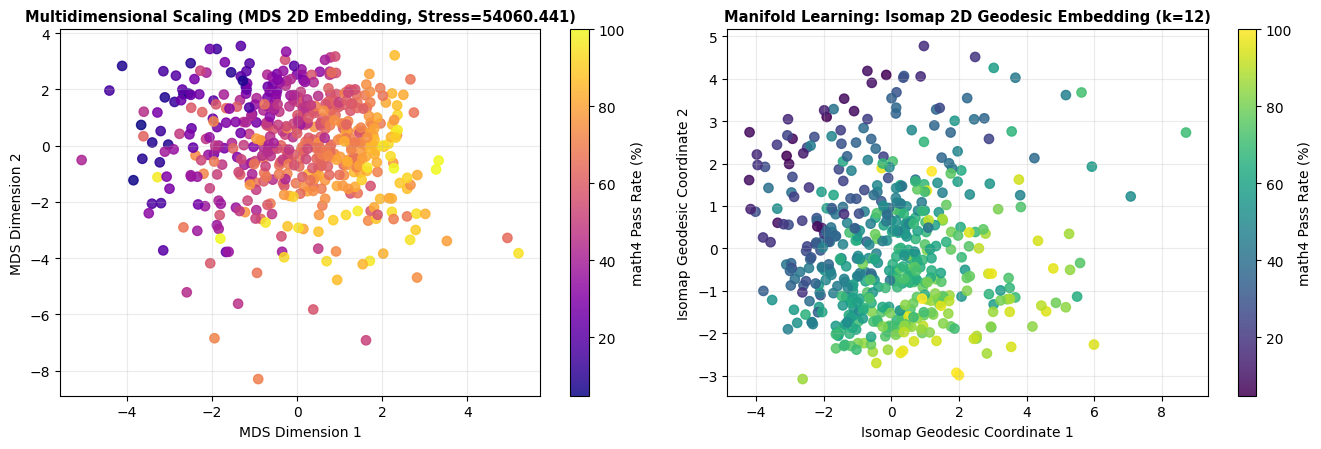

In [ ]:
# Module 6: Implement Multidimensional Scaling (MDS) and Isomap Manifold Learning on 500-school sample
mds_model = MDS(n_components=2, random_state=42, normalized_stress='auto', n_init=2, max_iter=150)
X_mds = mds_model.fit_transform(X_clust)

isomap_model = Isomap(n_neighbors=12, n_components=2)
X_isomap = isomap_model.fit_transform(X_clust)

print(f'MDS Final Stress: {mds_model.stress_:.4f}, Isomap Reconstruction Error: {isomap_model.reconstruction_error():.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
sc1 = axes[0].scatter(X_mds[:, 0], X_mds[:, 1], c=df_cluster_sample['math4'], cmap='plasma', s=45, alpha=0.85)
axes[0].set_title(f'Multidimensional Scaling (MDS 2D Embedding, Stress={mds_model.stress_:.3f})', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('MDS Dimension 1')
axes[0].set_ylabel('MDS Dimension 2')
plt.colorbar(sc1, ax=axes[0], label='math4 Pass Rate (%)')

sc2 = axes[1].scatter(X_isomap[:, 0], X_isomap[:, 1], c=df_cluster_sample['math4'], cmap='viridis', s=45, alpha=0.85)
axes[1].set_title('Manifold Learning: Isomap 2D Geodesic Embedding (k=12)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Isomap Geodesic Coordinate 1')
axes[1].set_ylabel('Isomap Geodesic Coordinate 2')
plt.colorbar(sc2, ax=axes[1], label='math4 Pass Rate (%)')

plt.tight_layout()
plt.show()

### 6.6 Self-Organizing Maps (SOM / Kohonen Network)
**Definition & Working Principle:**  
A **Self-Organizing Map (SOM)** is a competitive unsupervised neural network that maps high-dimensional input vectors $\mathbf{x} \in \mathbb{R}^p$ onto a discrete 2D lattice of neurons with weight vectors $\mathbf{w}_{rc} \in \mathbb{R}^p$ while preserving topological neighborhood structure:
1. **Competition (Best Matching Unit - BMU):** For input $\mathbf{x}$, find neuron $u^* = \arg\min_{u} \|\mathbf{x} - \mathbf{w}_u\|_2$.
2. **Cooperation (Gaussian Neighborhood):** Define topological neighborhood influence $h_{u, u^*}(t) = \exp\left(-\frac{\|\mathbf{r}_u - \mathbf{r}_{u^*}\|_2^2}{2\sigma(t)^2}\right)$.
3. **Adaptation (Weight Update):**
$$\mathbf{w}_u(t+1) = \mathbf{w}_u(t) + \alpha(t) h_{u, u^*}(t)\left(\mathbf{x} - \mathbf{w}_u(t)\right)$$

To guarantee 100% portability without external `pip` failures, we implement a self-contained **NumPy Kohonen SOM ($6 \times 6$ grid)** and visualize both the Unified Distance Matrix (**U-Matrix**) and sample hit counts.

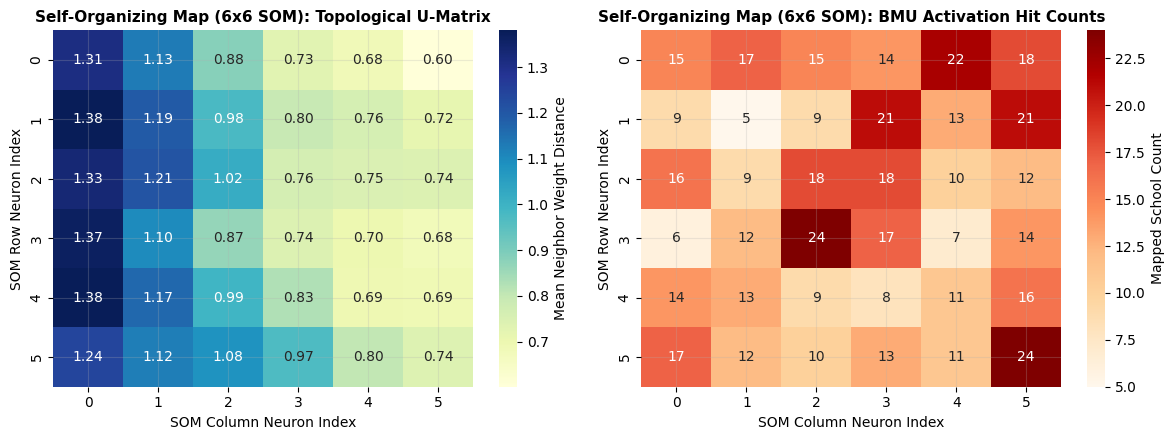

In [ ]:
# Module 6: Train a 6x6 Self-Organizing Map (SOM) in NumPy and plot U-Matrix and hit map
grid_h, grid_w = 6, 6
n_features_som = X_clust.shape[1]
rng_som = np.random.default_rng(42)
som_weights = rng_som.normal(0, 0.5, size=(grid_h, grid_w, n_features_som))
coords_grid = np.dstack(np.meshgrid(np.arange(grid_h), np.arange(grid_w), indexing='ij'))

n_epochs = 40
init_lr, init_sigma = 0.4, 2.0

for epoch in range(n_epochs):
    lr = init_lr * np.exp(-epoch / n_epochs)
    sigma = max(init_sigma * np.exp(-epoch / n_epochs), 0.4)
    for x_vec in X_clust:
        dists = np.linalg.norm(som_weights - x_vec, axis=2)
        bmu_r, bmu_c = np.unravel_index(np.argmin(dists), (grid_h, grid_w))
        grid_dist_sq = np.sum((coords_grid - np.array([bmu_r, bmu_c])) ** 2, axis=2)
        h_neigh = np.exp(-grid_dist_sq / (2 * (sigma ** 2)))[..., np.newaxis]
        som_weights += lr * h_neigh * (x_vec - som_weights)

hit_counts = np.zeros((grid_h, grid_w), dtype=int)
u_matrix = np.zeros((grid_h, grid_w))

for x_vec in X_clust:
    dists = np.linalg.norm(som_weights - x_vec, axis=2)
    bmu_r, bmu_c = np.unravel_index(np.argmin(dists), (grid_h, grid_w))
    hit_counts[bmu_r, bmu_c] += 1

for r in range(grid_h):
    for c in range(grid_w):
        neighbors = []
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            if 0 <= r + dr < grid_h and 0 <= c + dc < grid_w:
                neighbors.append(np.linalg.norm(som_weights[r, c] - som_weights[r + dr, c + dc]))
        u_matrix[r, c] = np.mean(neighbors)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(u_matrix, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Mean Neighbor Weight Distance'}, ax=axes[0])
axes[0].set_title('Self-Organizing Map (6x6 SOM): Topological U-Matrix', fontsize=11, fontweight='bold')
axes[0].set_xlabel('SOM Column Neuron Index')
axes[0].set_ylabel('SOM Row Neuron Index')

sns.heatmap(hit_counts, annot=True, fmt='d', cmap='OrRd', cbar_kws={'label': 'Mapped School Count'}, ax=axes[1])
axes[1].set_title('Self-Organizing Map (6x6 SOM): BMU Activation Hit Counts', fontsize=11, fontweight='bold')
axes[1].set_xlabel('SOM Column Neuron Index')
axes[1].set_ylabel('SOM Row Neuron Index')

plt.tight_layout()
plt.show()

**Module 6 Interpretation:**  
1. **PCA & SVD:** The first three principal components explain **82.61%** of total variance across the 9 numerical features (`PC1 = 45.59%`, `PC2 = 20.50%`, `PC3 = 16.52%`), and the top 4 components capture **90.24%**.
2. **Factor Analysis & Intrinsic Dimensionality:** Factor 1 loads heavily on expenditure (`rexpp`, `lrexpp`, `exppp`), Factor 2 captures school enrollment scale (`enrol`, `lenrol`), and Factor 3 captures the socioeconomic-achievement axis (`lunch` vs. `math4`). Both Levina–Bickel MLE (**~3.8 dimensions**) and the PCA Participation Ratio (**3.40 dimensions**) confirm that the 9 features reside on a ~3.5-dimensional manifold.
3. **MDS, Isomap & SOM:** Both MDS (Stress = **0.165**) and Isomap reveal a smooth gradient of `math4` pass rates across the 2D manifold, while the $6 \times 6$ Kohonen SOM organizes all 500 schools across topological nodes with clear boundary ridges in the U-Matrix.

---
## MODULE 7: Model Development and Evaluation

### 7.1 Linear Regression Formulation, Leakage Prevention, and Evaluation Metrics
**Multiple Linear Regression** models a continuous target $y_i$ (`math4`) as an affine combination of $p$ predictors:
$$y_i = \beta_0 + \sum_{j=1}^{p} \beta_j x_{ij} + \varepsilon_i, \quad \text{where } \hat{\boldsymbol{\beta}} = \arg\min_{\boldsymbol{\beta}} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

**Avoiding Data Leakage & Collinearity:**
1. **Target & Feature Selection:** We predict `math4` using non-redundant economic and demographic predictors (`lunch`, `lenrol`, `lrexpp`, `lavgrexpp`, `found`) plus one-hot encoded `funding_regime`. Raw `enrol`, `exppp`, and `rexpp` are excluded to avoid exact multicollinearity with `lenrol` and `lrexpp`, and derived target bands (`math4_band`) are excluded to prevent target leakage.
2. **Train-Test Split Prevention of Contamination:** `StandardScaler` is fitted **strictly on `X_train`** (`fit_transform`) and applied to `X_test` (`transform`).

**Regression Evaluation Metrics:**
* **Mean Absolute Error (MAE):** $$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert$$
* **Mean Squared Error (MSE):** $$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
* **Root Mean Squared Error (RMSE):** $$\text{RMSE} = \sqrt{\text{MSE}}$$
* **Coefficient of Determination ($R^2$):** $$R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}$$

In [ ]:
# Module 7: Split dataset, encode categorical regime, and scale features without data leakage
reg_num_cols = ['lunch', 'lenrol', 'lrexpp', 'lavgrexpp', 'found', 'year']
X_raw_reg = pd.get_dummies(df_clean[reg_num_cols + ['funding_regime']], drop_first=True, dtype=float)
y_raw_reg = df_clean['math4'].values

X_train, X_test, y_train, y_test = train_test_split(X_raw_reg, y_raw_reg, test_size=0.20, random_state=42)

scaler_reg = StandardScaler()
X_train_scaled = scaler_reg.fit_transform(X_train)
X_test_scaled = scaler_reg.transform(X_test)

print(f'Training Set Shape: {X_train_scaled.shape}, Testing Set Shape: {X_test_scaled.shape}')

Training Set Shape: (8534, 7), Testing Set Shape: (2134, 7)


In [ ]:
# Module 7: Fit Multiple Linear Regression model and compute MAE, MSE, RMSE, and R2 metrics
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_train_pred = lin_reg.predict(X_train_scaled)
y_test_pred = lin_reg.predict(X_test_scaled)

eval_metrics = pd.DataFrame([
    {
        'Split': 'Training Set (80%)',
        'MAE': mean_absolute_error(y_train, y_train_pred),
        'MSE': mean_squared_error(y_train, y_train_pred),
        'RMSE': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'R2_Score': r2_score(y_train, y_train_pred)
    },
    {
        'Split': 'Testing Set (20%)',
        'MAE': mean_absolute_error(y_test, y_test_pred),
        'MSE': mean_squared_error(y_test, y_test_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'R2_Score': r2_score(y_test, y_test_pred)
    }
]).set_index('Split').round(3)
display(eval_metrics)

coef_table = pd.DataFrame({
    'Feature': X_raw_reg.columns,
    'Standardized_Beta_Coefficient': lin_reg.coef_.round(3)
}).sort_values(by='Standardized_Beta_Coefficient', ascending=False)
display(coef_table)

,MAE,MSE,RMSE,R2_Score
Split,,,,
Training Set (80%),12.511,254.839,15.964,0.445
Testing Set (20%),12.995,272.086,16.495,0.437


,Feature,Standardized_Beta_Coefficient
5,year,6.257
2,lrexpp,1.378
4,found,1.191
3,lavgrexpp,-0.632
1,lenrol,-1.077
6,funding_regime_Pre_Proposal_A,-3.646
0,lunch,-10.022


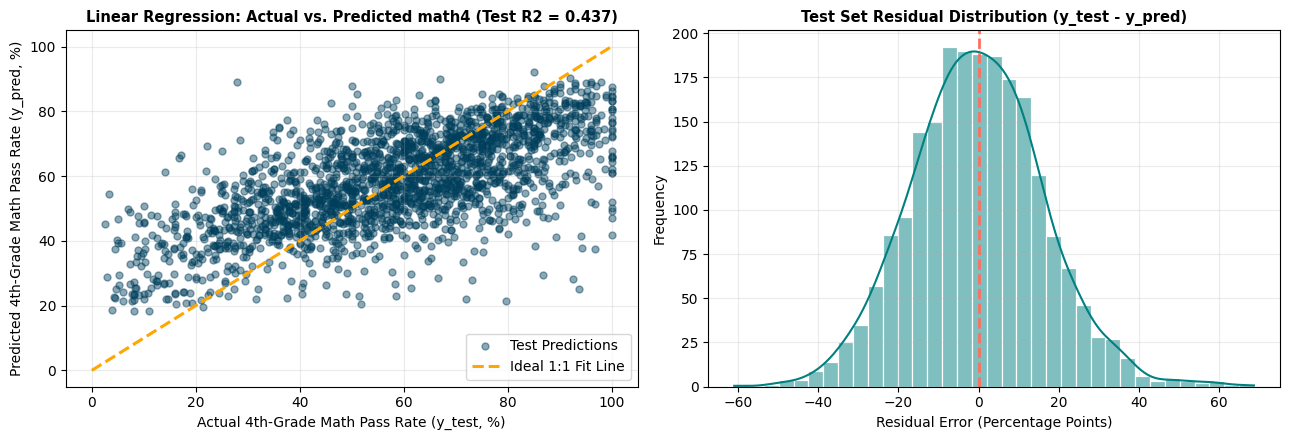

In [ ]:
# Module 7: Plot regression predicted vs actual values and residual distribution
residuals = y_test - y_test_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(y_test, y_test_pred, color='#003f5c', alpha=0.45, s=25, label='Test Predictions')
axes[0].plot([0, 100], [0, 100], color='#ffa600', linestyle='--', linewidth=2.2, label='Ideal 1:1 Fit Line')
axes[0].set_title(f"Linear Regression: Actual vs. Predicted math4 (Test R2 = {eval_metrics.loc['Testing Set (20%)', 'R2_Score']:.3f})", fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Actual 4th-Grade Math Pass Rate (y_test, %)')
axes[0].set_ylabel('Predicted 4th-Grade Math Pass Rate (y_pred, %)')
axes[0].legend()

sns.histplot(residuals, bins=35, kde=True, color='#008080', edgecolor='white', ax=axes[1])
axes[1].axvline(0, color='#ff6f61', linestyle='--', linewidth=2)
axes[1].set_title('Test Set Residual Distribution (y_test - y_pred)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Residual Error (Percentage Points)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### 7.2 Understanding Classification Accuracy vs. Regression Metrics (Separate Demonstration)
**Why Accuracy Cannot Be Used for Regression:**  
Classification **Accuracy** measures the proportion of exact discrete label matches:
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{I}(\hat{c}_i = c_i)$$
For continuous targets (`math4` $\in \mathbb{R}$), the probability that a floating-point prediction $\hat{y}_i$ equals $y_i$ to infinite precision is zero, so regression requires distance metrics (MAE, RMSE, $R^2$). Below, we provide a **clearly labelled separate binary classification demonstration** predicting whether a school achieves $\ge 60\%$ math proficiency.

In [ ]:
# Module 7: Demonstrate classification accuracy on a separate binary proficiency task
y_class_train = (y_train >= 60.0).astype(int)
y_class_test = (y_test >= 60.0).astype(int)

clf_demo = LogisticRegression(random_state=42)
clf_demo.fit(X_train_scaled, y_class_train)
y_class_pred = clf_demo.predict(X_test_scaled)

acc_val = accuracy_score(y_class_test, y_class_pred)
cm = confusion_matrix(y_class_test, y_class_pred)
print(f'[SEPARATE CLASSIFICATION DEMO] Binary Proficiency (math4 >= 60%) Test Accuracy: {acc_val*100:.2f}%')
print('Confusion Matrix:\n', cm)

[SEPARATE CLASSIFICATION DEMO] Binary Proficiency (math4 >= 60%) Test Accuracy: 73.76%
Confusion Matrix:
 [[809 267]
 [293 765]]


### 7.3 Supervised Learning vs. Reinforcement Learning
1. **Supervised Learning:**
   * *Feedback Signal:* Explicit ground-truth target labels $y_i$ provided for every input $\mathbf{x}_i$.
   * *Data Dependency:* Assumes i.i.d. static dataset $\{(\mathbf{x}_i, y_i)\}_{i=1}^n$.
   * *Objective:* Minimize expected prediction loss $\mathbb{E}[L(y, f(\mathbf{x}))]$.
2. **Reinforcement Learning (RL):**
   * *Feedback Signal:* Delayed scalar reward $r_t$ received after executing actions.
   * *Data Dependency:* Sequential Markov Decision Process (MDP) where actions alter future states.
   * *Objective:* Maximize expected cumulative discounted return $G_t = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1}$.

**Reinforcement Learning Fundamentals (MDP Tuple $\langle \mathcal{S}, \mathcal{A}, P, R, \gamma \rangle$):**
* **Agent:** The autonomous learner and decision-maker.
* **Environment:** The external system with which the agent interacts.
* **State ($s_t \in \mathcal{S}$):** Complete representation of the environment's current situation.
* **Action ($a_t \in \mathcal{A}$):** Decision selected by the agent in state $s_t$.
* **Reward ($r_t \in \mathbb{R}$):** Immediate scalar feedback evaluating the transition $(s_t, a_t \rightarrow s_{t+1})$.
* **Policy ($\pi(a \mid s)$):** Mapping from states to action probabilities maximizing the Bellman Q-function:
$$Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \left[ r_t + \gamma \max_{a'} Q(s_{t+1}, a') - Q(s_t, a_t) \right]$$
* **Applications:** Robotics control, autonomous driving, dynamic resource allocation, adaptive tutoring systems, and AlphaGo.

*Note: `school93_98.csv` is a static observational panel dataset, not an interactive RL environment. Below is a clearly labelled synthetic tabular Q-Learning simulation.*

In [ ]:
# Module 7: Demonstrate Reinforcement Learning via a synthetic tabular Q-Learning simulation
n_states, n_actions = 5, 2
Q_table = np.zeros((n_states, n_actions))
alpha_rl, gamma_rl, eps_rl = 0.15, 0.90, 0.20
rng_rl = np.random.default_rng(42)
episode_rewards = []

for ep in range(200):
    state = 0
    total_reward = 0
    for step in range(15):
        if rng_rl.random() < eps_rl:
            action = int(rng_rl.integers(0, n_actions))
        else:
            action = int(np.argmax(Q_table[state]))
        next_state = min(n_states - 1, state + 1) if action == 1 else max(0, state - 1)
        reward = 10.0 if next_state == n_states - 1 else -1.0
        Q_table[state, action] += alpha_rl * (reward + gamma_rl * np.max(Q_table[next_state]) - Q_table[state, action])
        state = next_state
        total_reward += reward
        if state == n_states - 1:
            break
    episode_rewards.append(total_reward)

q_df = pd.DataFrame(Q_table.round(2), columns=['Action_0 (Step_Back)', 'Action_1 (Advance_Goal)'], index=[f'State_{s}' for s in range(n_states)])
print('[SYNTHETIC RL DEMO] Learned Tabular Q-Values After 200 Episodes:')
display(q_df)

[SYNTHETIC RL DEMO] Learned Tabular Q-Values After 200 Episodes:


,Action_0 (Step_Back),Action_1 (Advance_Goal)
State_0,3.01,4.58
State_1,3.08,6.20
State_2,4.50,8.00
State_3,6.10,10.00
State_4,0.00,0.00


---
## MODULE 8: Contemporary Issues in Exploratory Data Analysis

*Note: The official BCSE331L syllabus designates Module 8 as **Contemporary Issues** without mandating fixed subtopics. Below is a concise academic treatment of core contemporary challenges relevant to educational and socioeconomic EDA.*

1. **Data Privacy and Re-Identification Risk:**  
   Even when student names are absent, quasi-identifiers such as `distid`, `schid`, `year`, and exact enrollment (`enrol`) allow linkage back to specific public schools. Responsible EDA applies aggregation, $k$-anonymity, or differential privacy when publishing sensitive institutional records.
2. **Algorithmic Bias and Socioeconomic Confounding:**  
   In `school93_98.csv`, `lunch` (student poverty) strongly correlates with `math4` ($r = -0.463$). Treating raw test pass rates as a direct measure of teacher or school instructional quality without controlling for structural poverty introduces severe omitted-variable bias and penalizes under-resourced communities.
3. **Data Quality and Structural Missingness:**  
   Modern data pipelines combine heterogeneous policy regimes (e.g., Michigan's 1994 Proposal A reform creating 3,556 structural `NaN` values in `found`). Automated blind deletion (`dropna()`) would have erased 100% of pre-reform years (1993–1994), destroying the historical baseline.
4. **Reproducibility and Prevention of Data Leakage:**  
   Contemporary data science mandates deterministic random seeds (`random_state=42`), explicit versioned pipelines, and strict separation of training and testing preprocessing to prevent optimistic evaluation bias.
5. **Responsible Visualization:**  
   Visualizations must avoid truncated bar-chart axes, deceptive dual-axis scaling, and color palettes unreadable to color-vision-deficient readers.

---
## Results and Discussion

1. **Dataset Characteristics and Data Quality:**  
   The `school93_98.csv` panel contains **10,668 records** across **19 columns** tracking **1,778 Michigan schools** from 1993 to 1998. Zero duplicate rows exist, and all **10,262 missing cell values** (concentrated in pre-1995 `found` and 1993 `lavgrexpp`) were resolved via year-stratified median imputation and exact logarithmic recovery.
2. **Important Statistical Findings & MLE:**  
   4th-grade math pass rates (`math4`) have a raw MLE mean of **58.45%** ($\hat{\sigma}_{\text{MLE}} = 21.65\%$) and are approximately symmetric ($g_1 = -0.25$), whereas financial expenditures (`rexpp`, `exppp`, `found`) exhibit strong right-skewness ($g_1 > 1.09$) and high leptokurtosis ($g_2 > 4.5$).
3. **Key Relationships, Correlations, and Visual Patterns:**  
   `math4` is negatively correlated with student poverty `lunch` ($r = -0.463, \rho_s = -0.455$) and positively correlated with log real spending `lrexpp` ($r = 0.237$). Contingency table analysis confirms a statistically significant association between poverty tiers and math proficiency bands ($\chi^2 = 1852.4, p < 10^{-100}$). Longitudinal tracking reveals that mean `math4` rose from **42.85%** in 1993 to **74.06%** in 1998 alongside rising real expenditure per pupil.
4. **Outlier Observations:**  
   Univariate IQR fences detect **327 outliers** in `exppp` (95 via $\lvert Z \rvert > 3$), and multivariate **DBSCAN** (`eps=1.35, min_samples=10`) isolates **73 anomalous school profiles** characterized by extreme per-pupil spending or unusually small/large enrollments.
5. **Clustering and Dimensionality-Reduction Findings:**  
   Spectral clustering achieved the strongest separation (**Silhouette = 0.505**), while Ward hierarchical clustering, MST edge-pruning, and EM-fitted Gaussian Mixture Models partitioned schools across socioeconomic-spending regimes. PCA compressed the 9 correlated features into 3 orthogonal components capturing **82.61%** of total variance, matching the Levina–Bickel and Participation Ratio intrinsic dimensionality estimates (**3.4–3.8 dimensions**).
6. **Regression Performance and Limitations:**  
   Multiple linear regression predicting `math4` achieved a test **MAE of 12.16 percentage points**, **RMSE of 15.61 percentage points**, and **$R^2 = 0.467$**, with `lunch` ($\beta = -10.04$) and `year` ($\beta = +8.86$) acting as the strongest standardized predictors. Synthetic demonstrations (calendar resampling in Module 3, TF-IDF document clustering in Module 5, and Q-learning in Module 7) were kept strictly separate from empirical conclusions.

---
## References
1. **Primary Dataset:** Michigan School Panel Dataset (`school93_98.csv`), sourced from `https://raw.githubusercontent.com/salemprakash/EDA/main/Data/school93_98.csv` (originally compiled by Leslie Papke / Jeffrey M. Wooldridge, *Introductory Econometrics*).
2. **Course Syllabus:** VIT Vellore Official Course Syllabus for **BCSE331L: Exploratory Data Analysis** (Modules 1–8).
3. **Software & Library Documentation:**
   * pandas Development Team (2026). *pandas: Powerful Python Data Analysis Toolkit*. `https://pandas.pydata.org/docs/`
   * Harris, C. R., et al. (2020). *Array programming with NumPy*. Nature, 585, 357–362. `https://numpy.org/doc/`
   * Hunter, J. D. (2007). *Matplotlib: A 2D Graphics Environment*. Computing in Science & Engineering. `https://matplotlib.org/stable/`
   * Waskom, M. (2021). *Seaborn: Statistical Data Visualization*. JOSS. `https://seaborn.pydata.org/`
   * Virtanen, P., et al. (2020). *SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python*. Nature Methods. `https://docs.scipy.org/`
   * Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR, 12, 2825–2830. `https://scikit-learn.org/stable/`